In [45]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import missingno as msno
import numpy as np
import pandas as pd
from sklearn.model_selection import TimeSeriesSplit

sys.path.insert(0, str(Path.cwd().parent))

from data_utils.fancy_barplot import fancy_bars
from data_utils.triple_plot import normality_report

In [46]:
datos_por_hoja = pd.read_excel("../data/Base_de_Datos.xlsx", sheet_name=None)
df_orec = datos_por_hoja["OREC"]
# 1. Asignar los valores de la fila 0 como nombres de columnas
df_orec.columns = df_orec.iloc[0]

# 2. Eliminar la fila 0 (que contiene los encabezados duplicados) y resetear el índice
df_orec = df_orec.iloc[1:].reset_index(drop=True)

# 3. Eliminar la primera columna
df_orec = df_orec.iloc[:, 1:]

# 4. Eliminar el nombre del eje de columnas
df_orec.columns.name = None

In [47]:
df_orec.head()

,Año,Mes,Dia,Turno,Proceso,Indice,KWH,KWH por proceso,Produccion (Equivalente),KWH/Equ (Reales),KWH/Equ (Presupuesto),Costo por KWH,Costo total KWH
0,2019,Oct,NaN,NaN,Rejillas,0.146401,577644,84567.536114,NaN,0,NaN,NaN,0
1,2019,Oct,NaN,NaN,Cinta,0.107361,577644,62016.19315,NaN,0,NaN,NaN,0
2,2019,Oct,NaN,NaN,Planta Oxido,0.370882,577644,214237.758155,NaN,0,NaN,NaN,0
3,2019,Oct,NaN,NaN,Empaste Casting,0.097601,577644,56378.357409,NaN,0,NaN,NaN,0
4,2019,Oct,NaN,NaN,Empaste Expanded,0.117121,577644,67654.028891,NaN,0,NaN,NaN,0


# Analizar Nulos

In [48]:
def nan_diagnosis(df: pd.DataFrame, name: str = "el df") -> None:
    """Return a graph that show null values."""
    n_cols = len(df.columns)
    ancho = max(10, int(n_cols * 0.35))
    alto = 5

    tamano_letra = max(6, 10 - n_cols // 10)

    # Porcentaje de nulos por columna
    pct_nulos = df.isnull().mean() * 100

    try:
        ax = msno.matrix(df, figsize=(ancho, alto), fontsize=tamano_letra) or plt.gca()
        plt.title(f"Patrón de Faltantes en {name}")

        if len(ax.get_xticks()) == n_cols:
            ax.set_xticks(range(n_cols))
            ax.set_xticklabels(
                [f"{c} ({p:.1f}%)" for c, p in zip(df.columns, pct_nulos, strict=False)],
                rotation=45,
                ha="left",
                fontsize=tamano_letra,
            )

        plt.show()

    except Exception:
        plt.figure(figsize=(ancho, alto))
        missing_pattern = df.isnull()

        plt.imshow(missing_pattern.astype(int), aspect="auto", cmap="RdYlGn_r")

        plt.xticks(
            ticks=range(n_cols),
            labels=[
                f"{c} ({p:.1f}%)" for c, p in zip(missing_pattern.columns, pct_nulos, strict=False)
            ],
            rotation=90,
            fontsize=tamano_letra,
            ha="center",
        )
        plt.yticks([])
        plt.title("Patrón de Faltantes (blanco = faltante)")
        plt.colorbar(label="1=Faltante, 0=Presente")

        plt.tight_layout()  # Evita que las etiquetas se corten abajo
        plt.show()

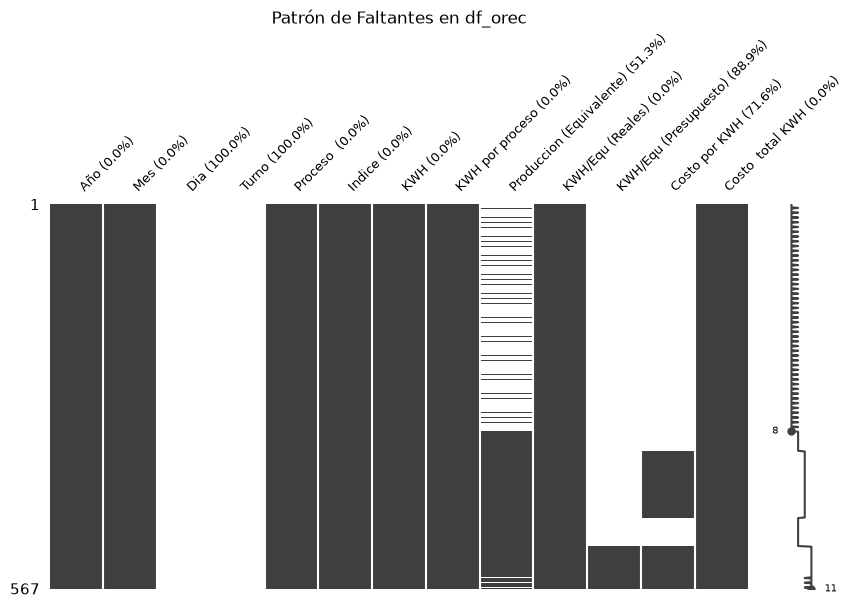

In [49]:
nan_diagnosis(df_orec, name="df_orec")

In [50]:
no_orec = df_orec[df_orec["Proceso "] != "OREC"]["Produccion (Equivalente)"]
solo_orec = df_orec[df_orec["Proceso "] == "OREC"]["Produccion (Equivalente)"]

print(f"Null values in non-OREC rows: {no_orec.isnull().sum()}")
print(f"Null values in OREC rows: {solo_orec.isnull().sum()}")

Null values in non-OREC rows: 291
Null values in OREC rows: 0


In [51]:
df_orec[df_orec["Proceso "] != "OREC"]["Produccion (Equivalente)"] * df_orec[
    df_orec["Proceso "] != "OREC"
]["Indice"]

0              NaN
1              NaN
2              NaN
3              NaN
4              NaN
          ...     
561    1029.919106
562    6346.085549
563    2036.088271
564            NaN
565    2868.960873
Length: 486, dtype: object

Al parecer 'Produccion (Equivalente) en un punto no se separaba por subprocesos.

In [52]:
df_orec.drop(columns=["Dia", "Turno"], inplace=True)

# Transformar al tipo correcto

In [53]:
df_orec = df_orec.rename(columns={"Costo  total KWH": "Costo total KWH"})

In [54]:
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Año                       567 non-null    object
 1   Mes                       567 non-null    str   
 2   Proceso                   567 non-null    str   
 3   Indice                    567 non-null    object
 4   KWH                       567 non-null    object
 5   KWH por proceso           567 non-null    object
 6   Produccion (Equivalente)  276 non-null    object
 7   KWH/Equ (Reales)          567 non-null    object
 8   KWH/Equ (Presupuesto)     63 non-null     object
 9   Costo por KWH             161 non-null    object
 10  Costo total KWH           567 non-null    object
dtypes: object(9), str(2)
memory usage: 56.4+ KB


In [55]:
cols_numericas = [
    "Año",
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_numericas:
    df_orec[col] = (
        df_orec[col]
        .astype(str)
        .str.strip()
        # Nota: en esta base el punto es el separador DECIMAL (0 valores con
        # coma, 567 con punto), por eso NO se eliminan los puntos.
        .str.replace(",", ".", regex=False)  # Convierte coma decimal a punto
    )

# 2. Conversión a tipos de datos específicos

# Año e Indice a enteros (usando Int64 para soportar posibles valores nulos)
df_orec["Año"] = pd.to_numeric(df_orec["Año"], errors="coerce").astype("Int64")
df_orec["Indice"] = pd.to_numeric(df_orec["Indice"], errors="coerce")
# Columnas continuas/métricas a flotantes (float64)
cols_float = [
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

for col in cols_float:
    df_orec[col] = pd.to_numeric(df_orec[col], errors="coerce")

# Columnas de texto/categoría
df_orec["Mes"] = df_orec["Mes"].astype("category")  # o .astype(str)

# Verifica el resultado
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 11 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   Año                       567 non-null    Int64   
 1   Mes                       567 non-null    category
 2   Proceso                   567 non-null    str     
 3   Indice                    567 non-null    float64 
 4   KWH                       567 non-null    float64 
 5   KWH por proceso           567 non-null    float64 
 6   Produccion (Equivalente)  276 non-null    float64 
 7   KWH/Equ (Reales)          567 non-null    float64 
 8   KWH/Equ (Presupuesto)     63 non-null     float64 
 9   Costo por KWH             161 non-null    float64 
 10  Costo total KWH           567 non-null    float64 
dtypes: Int64(1), category(1), float64(8), str(1)
memory usage: 51.6 KB


In [56]:
meses_abr = {
    "ene": 1,
    "feb": 2,
    "mar": 3,
    "abr": 4,
    "may": 5,
    "jun": 6,
    "jul": 7,
    "ago": 8,
    "sep": 9,
    "oct": 10,
    "nov": 11,
    "dic": 12,
}

# 1. Limpiar texto y mapear a número
mes_num = (
    df_orec["Mes"]
    .astype(str)
    .str.strip()
    .str.lower()
    .str.replace(".", "", regex=False)  # Quita puntos si vienen como 'Ene.'
    .map(meses_abr)
)

# 2. Crear la columna de Fecha (primer día de cada mes)
df_orec["Fecha"] = pd.to_datetime(
    {"year": df_orec["Año"], "month": mes_num, "day": 1}, errors="coerce"
)

In [57]:
base_fecha = pd.to_datetime(df_orec["Fecha"])

# 2. Número de aparición (0, 1, 2, ...) dentro de cada grupo Año-Mes
k = df_orec.groupby(["Año", "Mes"]).cumcount()

# 3. Total de registros por cada grupo Año-Mes
n = df_orec.groupby(["Año", "Mes"])["Fecha"].transform("count")

# 4. Total de días del mes específico (considera años bisiestos automáticamente)
dias_en_mes = base_fecha.dt.days_in_month

# 5. Calcular el día correspondiente con distribución uniforme entre el día 1 y el último día del
# mes
# Para n == 1 el incremento es 0 (queda día 1). Para n > 1 el último registro queda cerca del final
# del mes.
incremento_dias = (k * (dias_en_mes - 1) / (n - 1).replace(0, 1)).round()

# 6. Sumar los días a la fecha base (día 1)
df_orec["Fecha"] = base_fecha + pd.to_timedelta(incremento_dias, unit="D")

In [58]:
df_orec["Fecha"]

0     2019-10-01
1     2019-10-06
2     2019-10-11
3     2019-10-16
4     2019-10-21
         ...    
562   2026-06-11
563   2026-06-15
564   2026-06-20
565   2026-06-25
566   2026-06-30
Name: Fecha, Length: 567, dtype: datetime64[us]

# Split the data

In [59]:
df_orec.info()

<class 'pandas.DataFrame'>
RangeIndex: 567 entries, 0 to 566
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   Año                       567 non-null    Int64         
 1   Mes                       567 non-null    category      
 2   Proceso                   567 non-null    str           
 3   Indice                    567 non-null    float64       
 4   KWH                       567 non-null    float64       
 5   KWH por proceso           567 non-null    float64       
 6   Produccion (Equivalente)  276 non-null    float64       
 7   KWH/Equ (Reales)          567 non-null    float64       
 8   KWH/Equ (Presupuesto)     63 non-null     float64       
 9   Costo por KWH             161 non-null    float64       
 10  Costo total KWH           567 non-null    float64       
 11  Fecha                     567 non-null    datetime64[us]
dtypes: Int64(1), category(1), datetim

In [60]:
# El split tiene que ser temporal, asi que las filas se ordenan por fecha antes
# de partirlas. df_orec no se toca: las secciones de series de tiempo dependen
# de el. El indice original se conserva, para poder rastrear cada fila.
orden = df_orec.sort_values("Fecha")

X = orden.drop(columns=["Mes", "Año", "Produccion (Equivalente)"])
y = orden["Produccion (Equivalente)"]
X.shape, y.shape

((567, 9), (567,))

In [61]:
# Split temporal: el ultimo fold de TimeSeriesSplit deja todo el pasado en train y el
# futuro en test.
CORTE = "2025-01-01"
test_size = int((X["Fecha"] >= CORTE).sum())  # alineado a inicio de mes

# n_splits=2 es el minimo que admite sklearn; solo interesa el ultimo fold, el que
# entrena con todo lo anterior al corte. El corte se expresa en fechas y no en un
# numero de filas porque los meses no tienen todos 7 registros (2019-12 tiene 6,
# 2026-12 tiene 1).
tscv = TimeSeriesSplit(n_splits=2, test_size=test_size)
*_, (i_train, i_test) = tscv.split(X)

X_train, X_test = X.iloc[i_train], X.iloc[i_test]
y_train, y_test = y.iloc[i_train], y.iloc[i_test]

In [62]:
print(
    f"train {X_train['Fecha'].min():%Y-%m} -> {X_train['Fecha'].max():%Y-%m}"
    f"  ({len(X_train)} filas)"
)
print(
    f"test  {X_test['Fecha'].min():%Y-%m} -> {X_test['Fecha'].max():%Y-%m}  ({len(X_test)} filas)"
)
print(
    f"sin solape: {X_train['Fecha'].max() < X_test['Fecha'].min()}  |  "
    f"target no nulo: train={y_train.notna().sum()} test={y_test.notna().sum()}"
)
X_train.shape, X_test.shape

train 2019-10 -> 2024-12  (440 filas)
test  2025-01 -> 2026-12  (127 filas)
sin solape: True  |  target no nulo: train=152 test=124


((440, 9), (127, 9))

In [63]:
df_train = pd.concat([X_train, y_train], axis=1)

# Iniciar el análisis exploratorio de datos (EDA) con las funciones personalizadas

In [64]:
df_train.columns

Index(['Proceso ', 'Indice', 'KWH', 'KWH por proceso', 'KWH/Equ (Reales)',
       'KWH/Equ (Presupuesto)', 'Costo por KWH', 'Costo total KWH', 'Fecha',
       'Produccion (Equivalente)'],
      dtype='str')

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 7 distinct values across 440 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


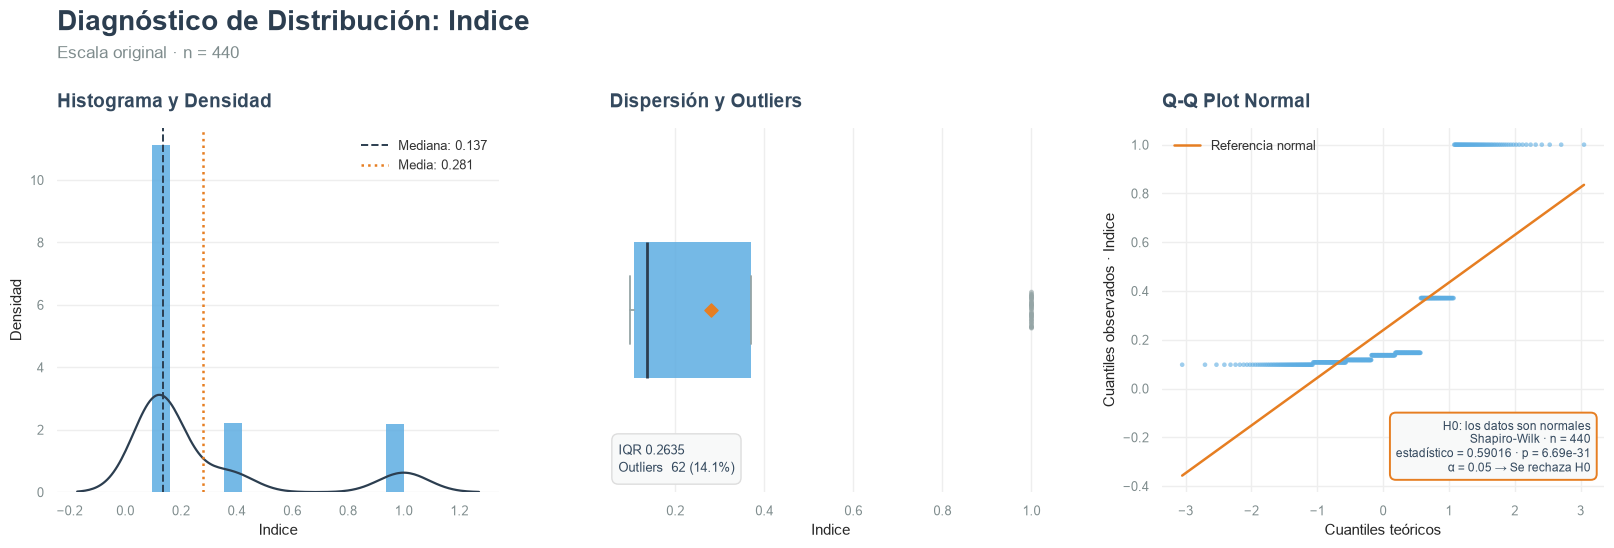

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 63 distinct values across 440 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


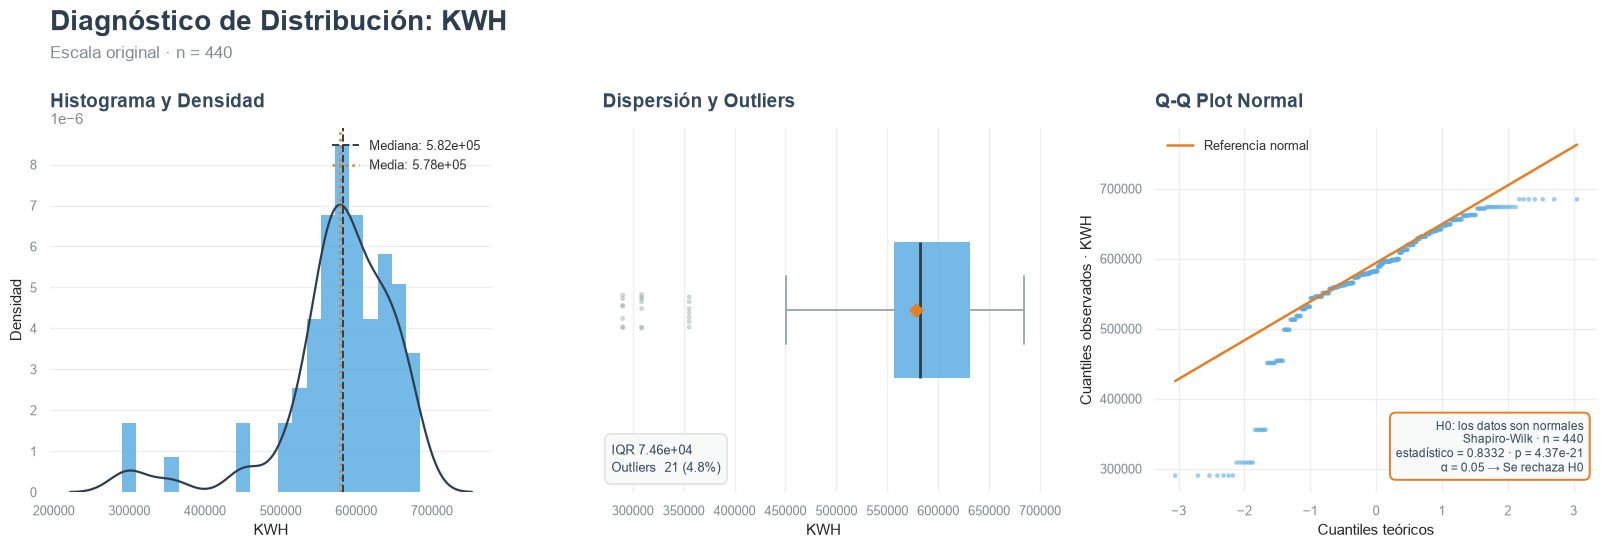

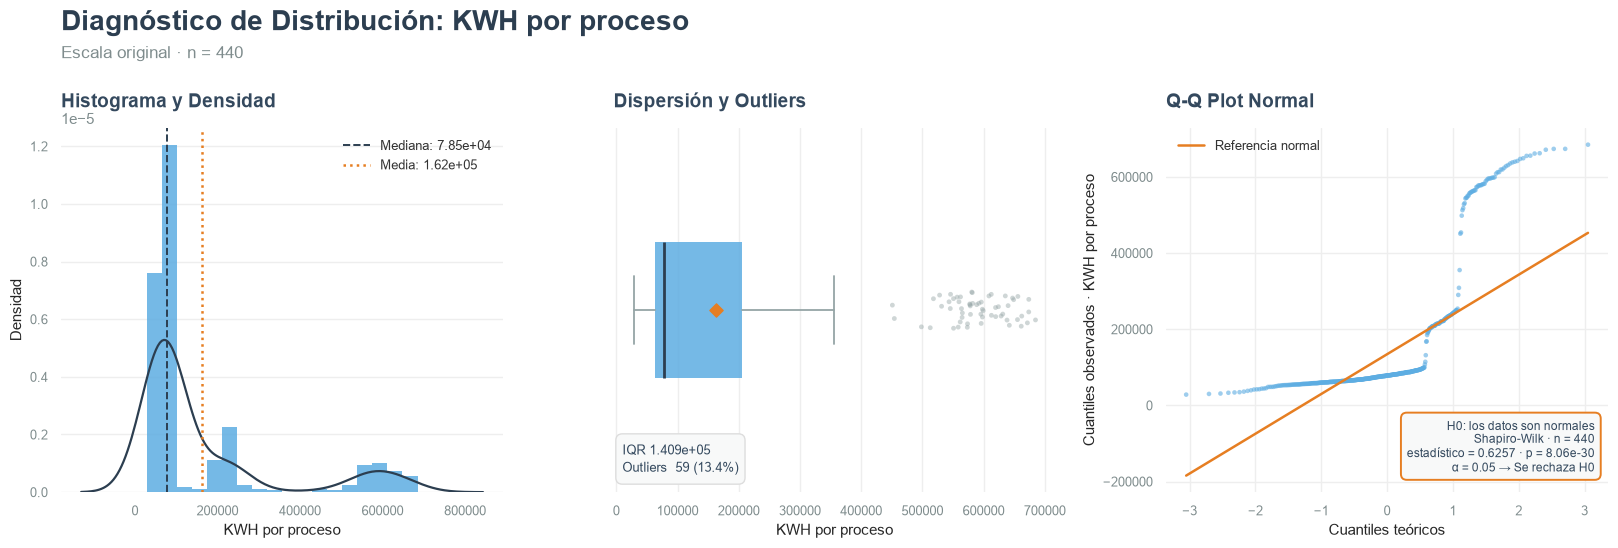

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 153 distinct values across 440 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


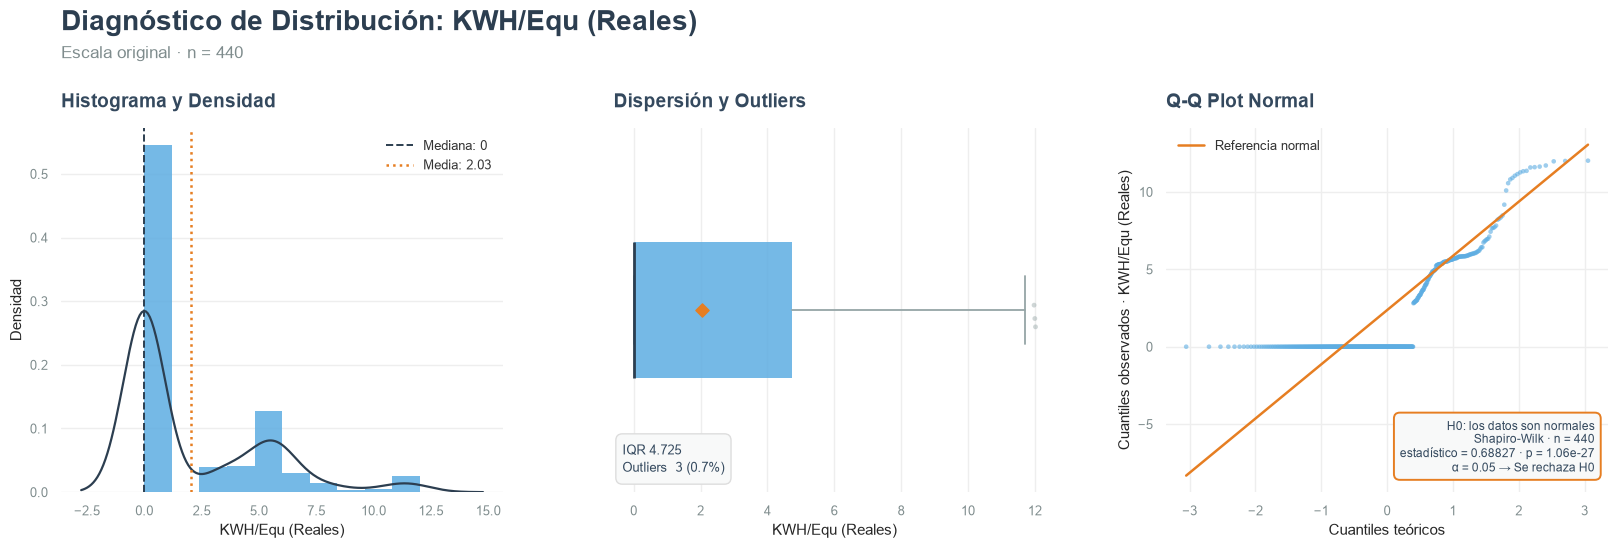

KWH/Equ (Presupuesto): 0 valores validos en train, se omite (se registra desde una fecha posterior al corte)


d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 11 distinct values across 76 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


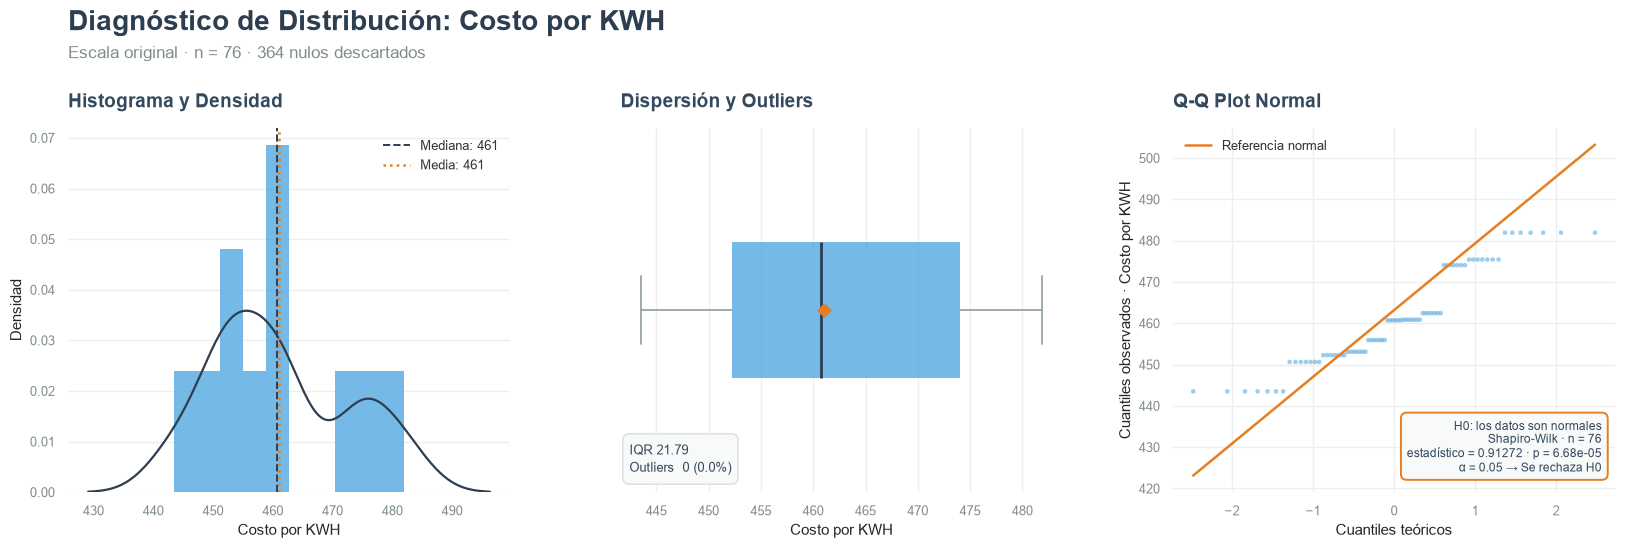

d:\Externado\Catch_2026\clarios_app\data_utils\triple_plot.py:641: UserWarning: Shapiro-Wilk assumes a continuous distribution, but the sample has 77 distinct values across 440 observations. With that many ties the statistic is biased and the p-value is not interpretable.
  name, statistic, p_value, n_test = _normality_test(xs, test)


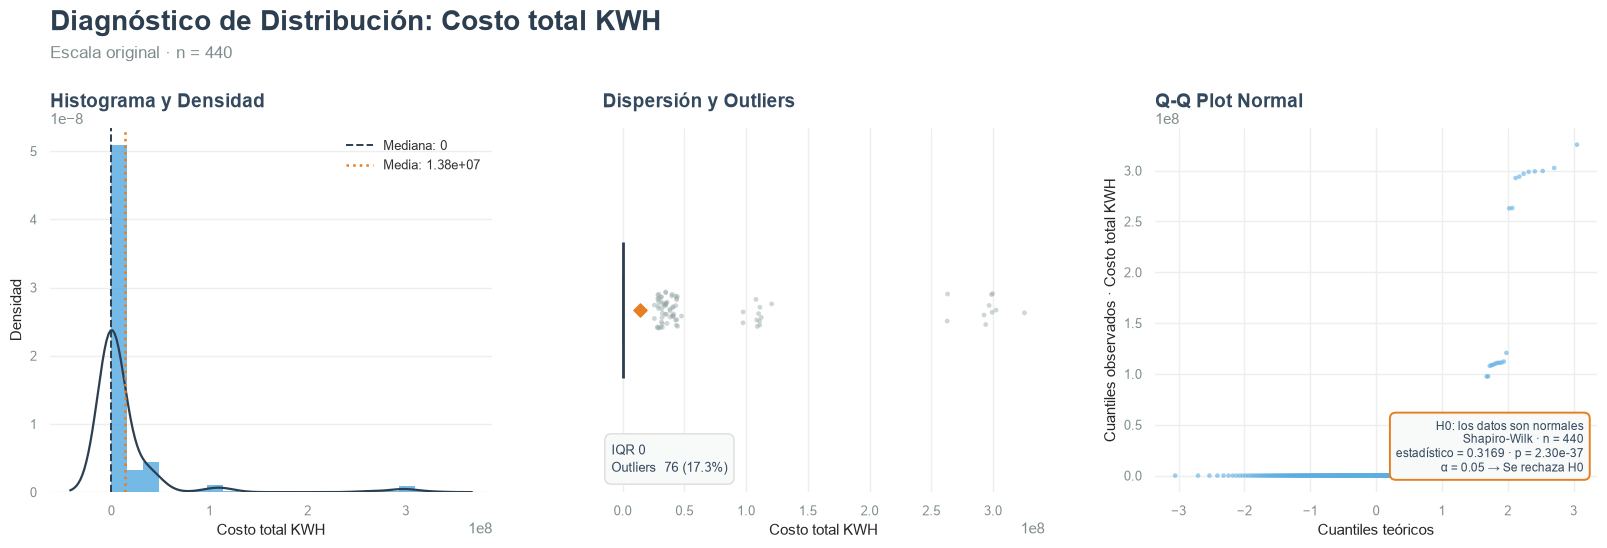

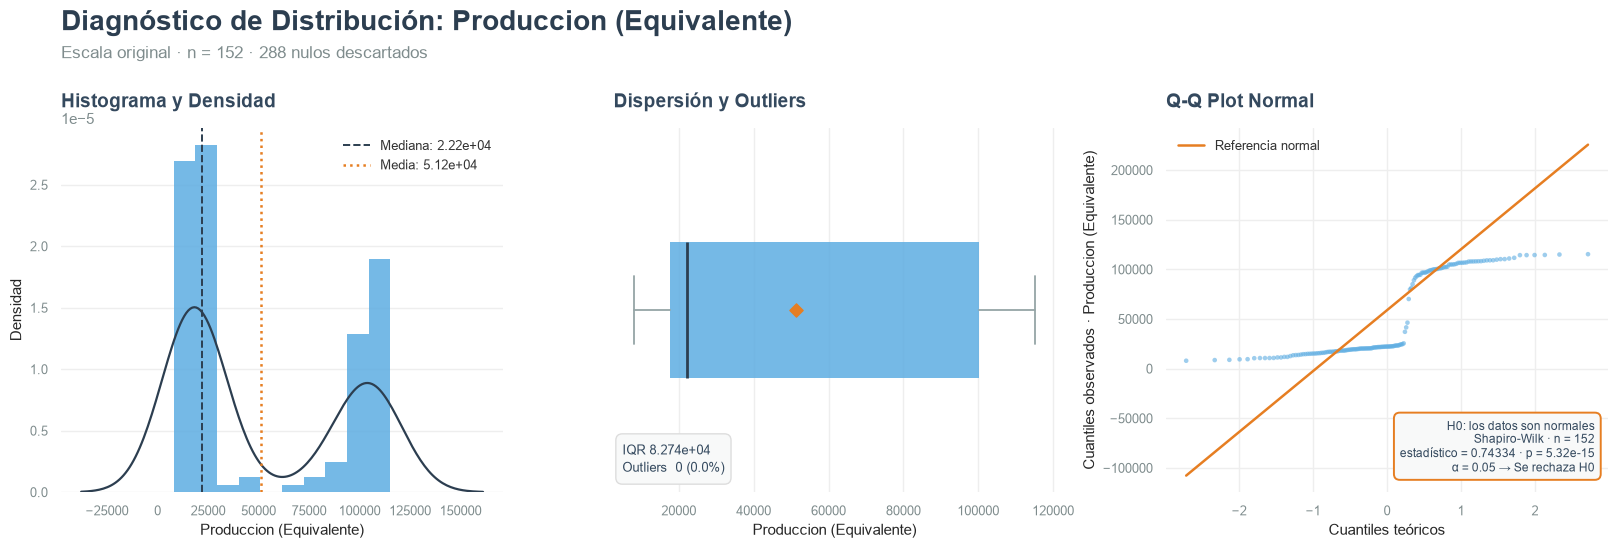

In [65]:
# El split es temporal, asi que una columna que empieza a registrarse tarde puede
# quedar vacia en train: KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de la
# ventana de test. normality_report exige un minimo de 8 valores, asi que se avisa
# y se sigue en vez de cortar el notebook.
MIN_VALIDOS = 8

for col in df_train.columns:
    if df_train[col].dtype == "int64" or df_train[col].dtype == "float64":
        validos = df_train[col].dropna().size
        if validos < MIN_VALIDOS:
            print(
                f"{col}: {validos} valores validos en train, se omite "
                f"(se registra desde una fecha posterior al corte)"
            )
            continue
        normality_report(df_train, col)

La fabrica tiene 2 picos en sus valores de produccion, sin embargo es valioso filtrar solo por orec para no caer en conclusiones desasertadas que estan separadas por proceso.

<Axes: title={'left': 'Distribución de Proceso '}, xlabel='Proceso ', ylabel='Conteo'>

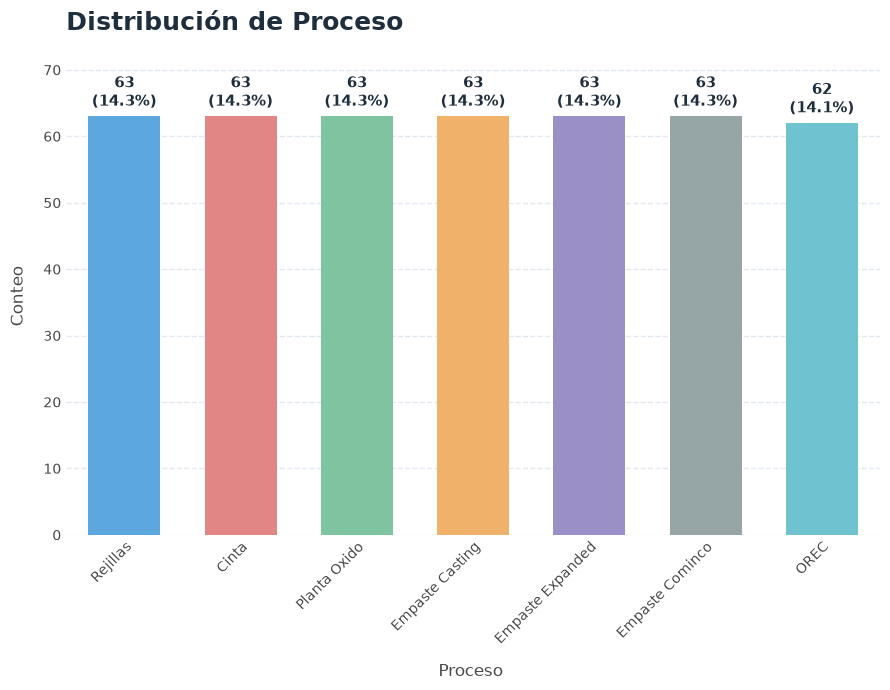

In [66]:
fancy_bars(df_train, "Proceso ", labels="both", rot=45)

## Ahondando en los atipicos

In [67]:
cols = ["Costo total KWH", "Costo por KWH", "KWH/Equ (Reales)", "KWH por proceso"]

# Los ceros y nulos son estructurales (proceso sin registro), no mediciones:
# incluirlos deformaria el IQR. Todo se calcula sobre valores > 0.
resumen = []
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    resumen.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max/mediana": s.max() / s.median(),
        }
    )

pd.DataFrame(resumen).round(1)

,columna,n,atipicos,mediana,maximo,max/mediana
0,Costo total KWH,157,20,38632830.9,354132062.7,9.2
1,Costo por KWH,161,0,513.1,568.5,1.1
2,KWH/Equ (Reales),275,38,5.6,944.1,168.6
3,KWH por proceso,563,75,77466.9,684713.0,8.8


In [68]:
# Algunos valores atipicos concretos (los 5 mas altos de cada columna)
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    print(f"{col} -> {len(atipicos)} atipicos")
    print(atipicos.nlargest(5).to_string())

Costo total KWH -> 20 atipicos
461    3.541321e+08
447    3.298550e+08
405    3.255245e+08
510    3.190903e+08
454    3.087664e+08
Costo por KWH -> 0 atipicos
Series([], )
KWH/Equ (Reales) -> 38 atipicos
522    944.051319
536     20.808488
541     15.556898
562     14.742852
513     14.646067
KWH por proceso -> 75 atipicos
405    684713.0
419    673740.0
223    673694.0
412    671460.0
356    662248.0


Costo total KWH        mediana=  38,632,830.9  max= 354,132,062.7  ordenes=0.96
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           5.6  max=         944.1  ordenes=2.23
KWH por proceso        mediana=      77,466.9  max=     684,713.0  ordenes=0.95


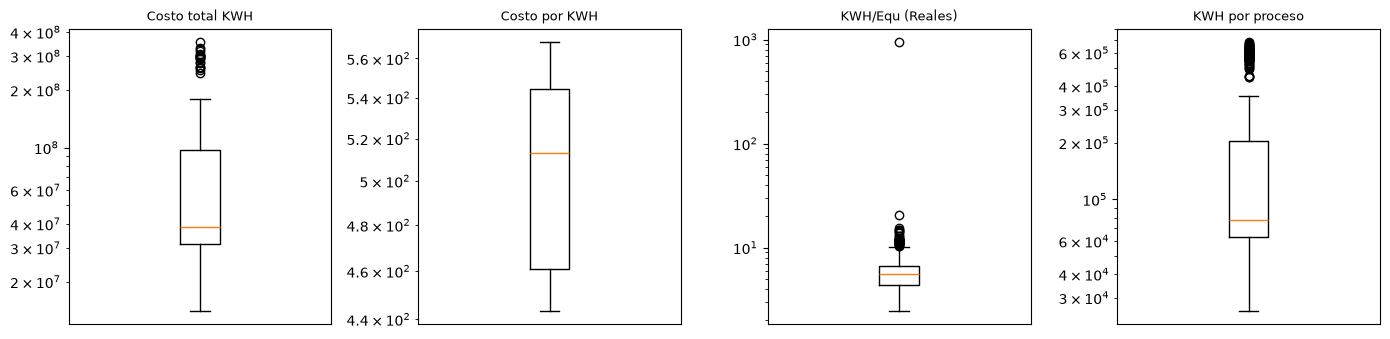

In [69]:
# Ordenes de magnitud entre el maximo y la mediana
for col in cols:
    s = df_orec.loc[df_orec[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

# Escala log: si la caja se ve aplastada contra el eje, la cola abarca ordenes de magnitud
fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_orec.loc[df_orec[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [70]:
# Metricas explicitas del resumen de abajo
filas = []
for col in cols:
    s = df_orec[col].dropna()
    s = s[s > 0]
    q1, q3 = s.quantile([0.25, 0.75])
    atipicos = s[s > q3 + 1.5 * (q3 - q1)]
    filas.append(
        {
            "columna": col,
            "n": len(s),
            "atipicos": len(atipicos),
            "mediana": s.median(),
            "maximo": s.max(),
            "max_sobre_mediana": s.max() / s.median(),
            "ordenes": np.log10(s.max() / s.median()),
            # Ceros y nulos contados sobre df_orec completo (567 filas)
            "ceros_df_orec": int((df_orec[col] == 0).sum()),
            "nulos_df_orec": int(df_orec[col].isna().sum()),
        }
    )

metricas_atipicos = pd.DataFrame(filas).round(2)
print(f"df_orec: {len(df_orec)} filas | df_train (temporal): {len(df_train)} filas")
metricas_atipicos

df_orec: 567 filas | df_train (temporal): 440 filas


,columna,n,atipicos,mediana,maximo,max_sobre_mediana,ordenes,ceros_df_orec,nulos_df_orec
0,Costo total KWH,157,20,38632830.91,3.541321e+08,9.17,0.96,410,0
1,Costo por KWH,161,0,513.14,5.684600e+02,1.11,0.04,0,406
2,KWH/Equ (Reales),275,38,5.60,9.440500e+02,168.60,2.23,292,0
3,KWH por proceso,563,75,77466.86,6.847130e+05,8.84,0.95,4,0


### Resumen de atipicos

**1. Atipicos reales** (IQR, solo valores > 0):

| columna | mediana | maximo | max/mediana | atipicos |
|---|---|---|---|---|
| `Costo total KWH` | 38,632,830.9 | 354,132,062.7 | 9.2x | 20 |
| `Costo por KWH` | 513.1 | 568.5 | 1.1x | 0 |
| `KWH/Equ (Reales)` | 5.6 | 944.1 | **168.6x** | 38 |
| `KWH por proceso` | 77,466.9 | 684,713.0 | 8.8x | 75 |

**2. Solo una columna crece por ordenes de magnitud.** `KWH/Equ (Reales)` llega a 168.6x
su mediana (~2.2 ordenes). Las demas se quedan en un factor de ~9x, es decir menos de un
orden de magnitud: tienen atipicos, pero de la misma escala que el resto.

**3. `Costo por KWH` no tiene atipicos** y es casi constante (513 a 568, apenas 1.1x). Es
una tarifa, no una medicion del proceso.

**4. Ceros y nulos son estructurales** y se excluyeron del calculo: `Costo total KWH`
tiene 410 ceros de 567 filas, `KWH/Equ (Reales)` 292, y `Costo por KWH` 406 nulos.
Incluirlos habria aplastado los cuartiles y escondido los atipicos.


In [71]:
# El registro extremo es un error de digitacion: crece varios ordenes de magnitud
# respecto a la mediana y al segundo valor mas alto.
# Se quita en una COPIA. df_orec no se modifica porque las secciones de series de
# tiempo de mas abajo dependen de el, y perderia un mes de Empaste Expanded.
# Nota: cae en 2025-12, dentro de la ventana de test, asi que df_train nunca lo tuvo.
df_sin_extremo = df_orec.drop(df_orec["KWH/Equ (Reales)"].idxmax())

Costo total KWH        mediana=  38,828,109.0  max= 354,132,062.7  ordenes=0.96
Costo por KWH          mediana=         513.1  max=         568.5  ordenes=0.04
KWH/Equ (Reales)       mediana=           5.6  max=          20.8  ordenes=0.57
KWH por proceso        mediana=      77,514.9  max=     684,713.0  ordenes=0.95


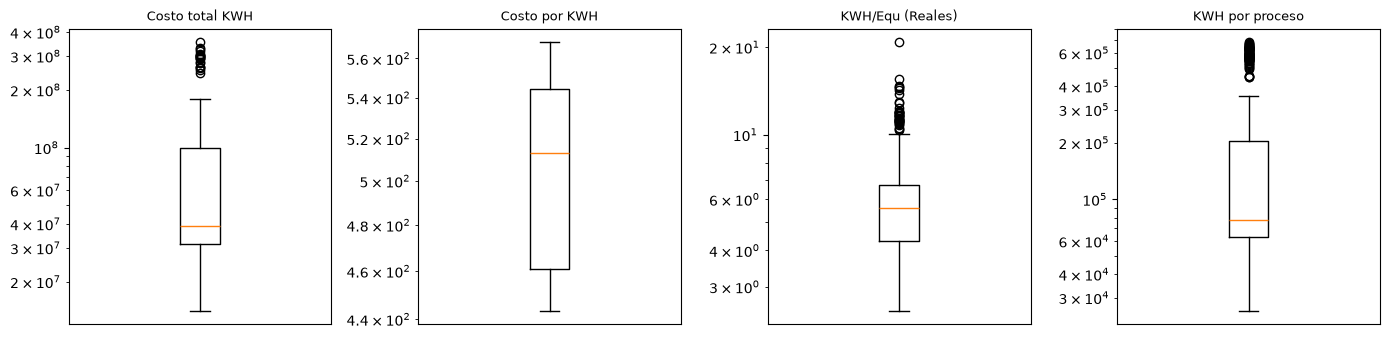

In [72]:
# Mismo analisis que arriba, ahora sobre el dataset sin el registro extremo
for col in cols:
    s = df_sin_extremo.loc[df_sin_extremo[col] > 0, col].dropna()
    print(
        f"{col:<22} mediana={s.median():>14,.1f}  max={s.max():>14,.1f}  "
        f"ordenes={np.log10(s.max() / s.median()):.2f}"
    )

fig, axes = plt.subplots(1, len(cols), figsize=(14, 3.5))
for ax, col in zip(axes, cols, strict=False):
    ax.boxplot(df_sin_extremo.loc[df_sin_extremo[col] > 0, col].dropna())
    ax.set_yscale("log")
    ax.set_title(col, fontsize=9)
    ax.set_xticks([])
plt.tight_layout()
plt.show()

In [73]:
# Ya no hace falta fijar el estado 'antes' a mano: la auditoria corre sobre df_orec,
# que no se modifica, asi que las dos mitades de la comparacion se calculan aqui.
def ordenes(d: pd.DataFrame, col: str) -> float:
    """Ordenes de magnitud entre el maximo y la mediana de `col`, sobre valores > 0."""
    s = d.loc[d[col] > 0, col].dropna()
    return np.log10(s.max() / s.median())


comparacion = pd.DataFrame(
    [
        {
            "columna": col,
            "ordenes_antes": round(ordenes(df_orec, col), 2),
            "ordenes_despues": round(ordenes(df_sin_extremo, col), 2),
            "solucionado": ordenes(df_sin_extremo, col) < 1,  # criterio: < 1 orden
        }
        for col in cols
    ]
)
comparacion

,columna,ordenes_antes,ordenes_despues,solucionado
0,Costo total KWH,0.96,0.96,True
1,Costo por KWH,0.04,0.04,True
2,KWH/Equ (Reales),2.23,0.57,True
3,KWH por proceso,0.95,0.95,True


In [74]:
# Metricas explicitas del resumen de abajo.
# El 'antes' es df_orec completo y el 'despues' la copia sin el registro
# extremo: la auditoria de calidad mira todo el historico, no solo el train.
antes = df_orec
despues = df_sin_extremo


def resumen_iqr(d: pd.DataFrame) -> pd.DataFrame:
    """Tabla IQR por columna: atipicos, maximo, razon max/mediana y ordenes."""
    filas = []
    for col in cols:
        s = d[col].dropna()
        s = s[s > 0]
        q1, q3 = s.quantile([0.25, 0.75])
        atipicos = s[s > q3 + 1.5 * (q3 - q1)]
        filas.append(
            {
                "columna": col,
                "atipicos": len(atipicos),
                "maximo": s.max(),
                "ratio": s.max() / s.median(),
                "ordenes": np.log10(s.max() / s.median()),
            }
        )
    return pd.DataFrame(filas).set_index("columna")


a, b = resumen_iqr(antes), resumen_iqr(despues)
metricas_verificacion = (
    a.join(b, lsuffix="_antes", rsuffix="_despues")
    .assign(solucionado=lambda t: t["ordenes_despues"] < 1)
    .reset_index()
    .round(2)
)
print(f"filas: {len(antes)} -> {len(despues)} (se elimino {len(antes) - len(despues)})")
metricas_verificacion

filas: 567 -> 566 (se elimino 1)


,columna,atipicos_antes,maximo_antes,ratio_antes,ordenes_antes,atipicos_despues,maximo_despues,ratio_despues,ordenes_despues,solucionado
0,Costo total KWH,20,3.541321e+08,9.17,0.96,20,3.541321e+08,9.12,0.96,True
1,Costo por KWH,0,5.684600e+02,1.11,0.04,0,5.684600e+02,1.11,0.04,True
2,KWH/Equ (Reales),38,9.440500e+02,168.60,2.23,37,2.081000e+01,3.72,0.57,True
3,KWH por proceso,75,6.847130e+05,8.84,0.95,75,6.847130e+05,8.83,0.95,True


### Verificacion: el problema de la columna quedo resuelto

- **`KWH/Equ (Reales)` corregida.** Pasa de **2.23 a 0.57 ordenes** de magnitud, y la
  razon max/mediana cae de **168.6x a 3.7x**. Queda por debajo del umbral de 1 orden, en
  linea con las otras tres columnas.
- **El nuevo maximo es 20.8**, en linea con el resto de la distribucion: ya no hay un
  salto aislado respecto al segundo valor mas alto.
- **Las otras tres columnas no se vieron afectadas.** Se elimino 1 fila de 567, y
  `Costo por KWH` (0.04), `KWH por proceso` (0.95) y `Costo total KWH` (0.96) quedan
  identicos. La eliminacion fue quirurgica.
- **Quedan 37 atipicos** por IQR en la columna, pero son cola normal de la distribucion,
  no un problema de escala: ese era el punto a resolver.


## Series de tiempo de las variables numericas

La base solo tiene `Año` y `Mes`: la columna `Fecha` reparte los registros entre los dias
del mes de forma artificial, asi que la granularidad real es **mensual**. Cada punto es el
promedio de los 7 procesos de ese mes. La serie se corta en **2026-06**, el ultimo mes
completo.

Estas secciones usan **todo el historico**, no solo la ventana de train: son
descriptivas, no alimentan ningun modelo, y el deterioro que analizan ocurre justo en
2025-2026. La banda gris de cada grafico marca la ventana de test (desde `2025-01`),
para que se vea que parte de la serie quedo fuera del entrenamiento.


In [75]:
num_cols = [
    "Indice",
    "KWH",
    "KWH por proceso",
    "Produccion (Equivalente)",
    "KWH/Equ (Reales)",
    "KWH/Equ (Presupuesto)",
    "Costo por KWH",
    "Costo total KWH",
]

# Granularidad real = mensual; promedio entre los 7 procesos de cada mes.
# Se corta en 2026-06: despues solo hay un registro suelto en 2026-12.
# Fecha reparte el dia dentro del mes de forma artificial, asi que se normaliza a
# inicio de mes ANTES de filtrar: si no, junio 2026 promedia 1 de sus 7 filas.
mes_completo = df_orec["Fecha"].dt.to_period("M").dt.to_timestamp()
completo = df_orec[mes_completo <= "2026-06-01"]
serie = completo.groupby(mes_completo.loc[completo.index])[num_cols].mean()

serie.shape

(81, 8)

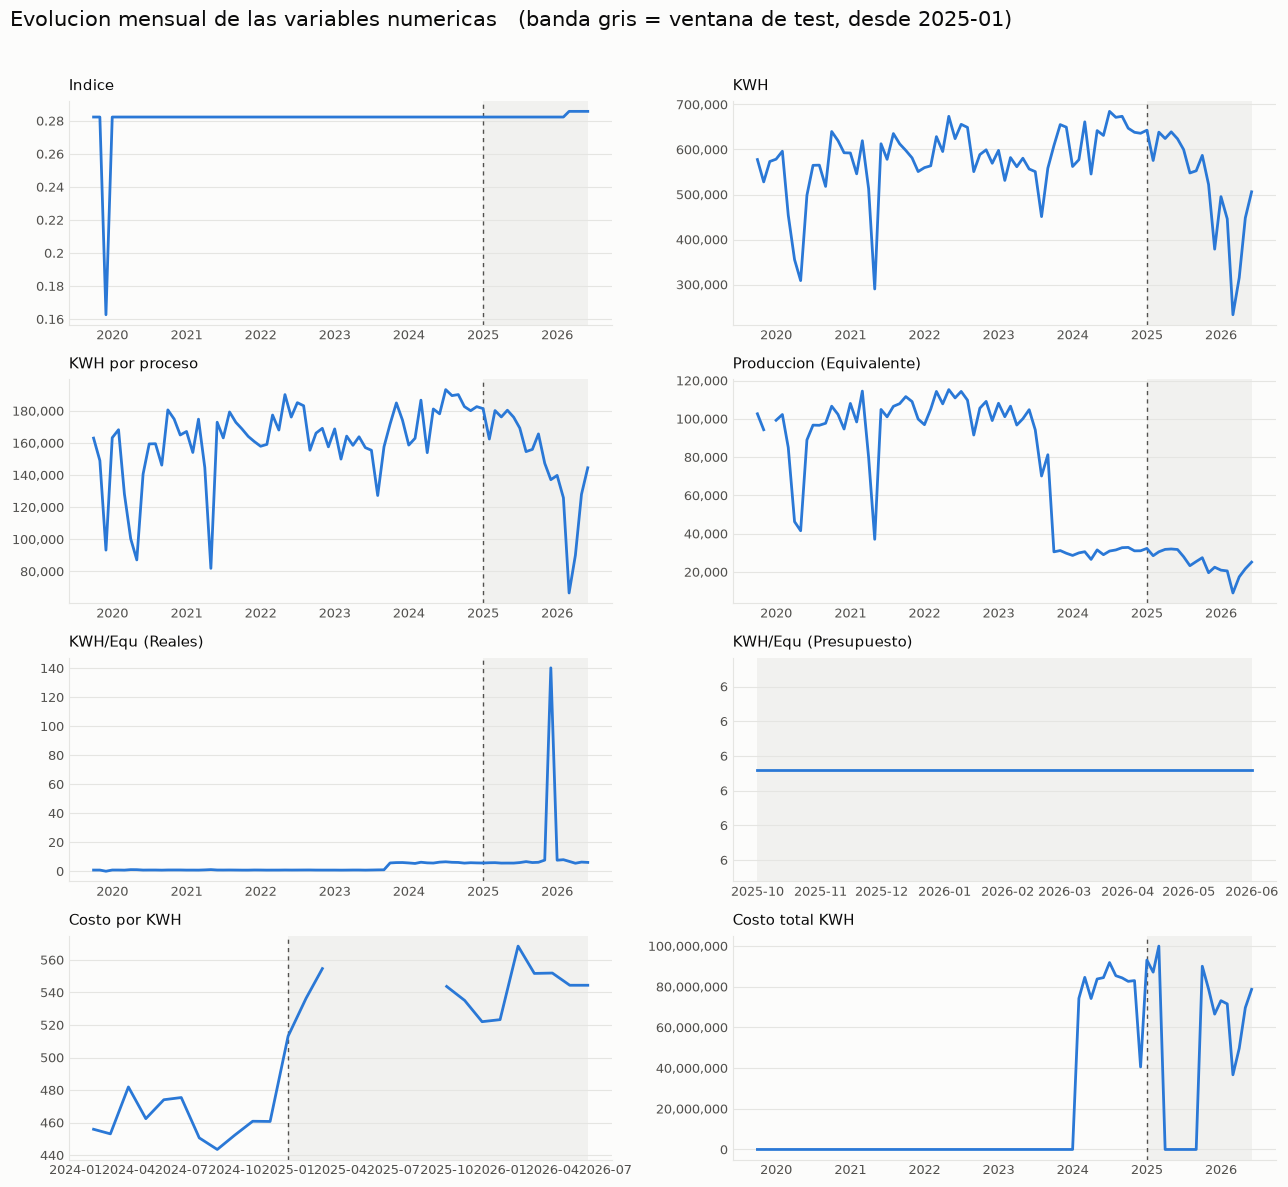

In [76]:
# Paleta validada (skill dataviz): linea, superficie, tinta y grilla
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Las series cubren todo el historico, pero el split es temporal: esta funcion sombrea
# la ventana de test para que se vea que parte quedo fuera del entrenamiento.
# CORTE viene de la celda del split, asi la banda sigue al corte y no se repite el dato.
CORTE_TS = pd.Timestamp(CORTE)


def marcar_test(
    ax: plt.Axes, desde: pd.Timestamp, hasta: pd.Timestamp, etiqueta: bool = False
) -> None:
    """Sombrea la ventana de test, recortada al rango que ya ocupa la serie."""
    # El rango se pasa explicito: ax.get_xlim() devuelve numeros de fecha de matplotlib
    # y mezclarlos con un Timestamp en axvspan falla. Recortar a [desde, hasta] evita
    # que la banda estire el eje de un panel cuyos datos empiezan despues del corte
    # (KWH/Equ (Presupuesto) arranca en 2025-10, ya dentro de test).
    if hasta < CORTE_TS:
        return  # el panel termina antes del corte: no hay ventana de test que marcar
    ax.axvspan(max(CORTE_TS, desde), hasta, color=GRILLA, alpha=0.45, zorder=0, linewidth=0)
    if desde <= CORTE_TS:
        ax.axvline(CORTE_TS, color=TINTA_SUAVE, linewidth=1, linestyle=(0, (3, 3)), zorder=2)
    if etiqueta:
        ax.annotate(
            "ventana de test",
            xy=(CORTE_TS, 1),
            xycoords=("data", "axes fraction"),
            xytext=(5, -12),
            textcoords="offset points",
            color=TINTA_SUAVE,
            fontsize=8,
        )


fig, axes = plt.subplots(4, 2, figsize=(13, 12), facecolor=SUPERFICIE)
fig.suptitle(
    "Evolucion mensual de las variables numericas   (banda gris = ventana de test, desde 2025-01)",
    fontsize=15,
    color=TINTA,
    x=0.01,
    ha="left",
    y=0.985,
)

for ax, col in zip(axes.ravel(), num_cols, strict=False):
    ax.plot(serie.index, serie[col], color=LINEA, linewidth=2, zorder=3)
    visible = serie[col].replace(0, np.nan).dropna()
    marcar_test(ax, visible.index[0], visible.index[-1])
    ax.set_title(col, fontsize=10.5, color=TINTA, loc="left", pad=8)
    ax.set_facecolor(SUPERFICIE)
    ax.grid(axis="y", color=GRILLA, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.spines[["left", "bottom"]].set_color(GRILLA)
    ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
    ax.yaxis.set_major_formatter(lambda v, _: f"{v:,.0f}" if abs(v) >= 1 else f"{v:g}")

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [77]:
# Metricas explicitas del resumen de abajo
mes = df_orec["Fecha"].dt.to_period("M").dt.to_timestamp()
hasta_junio = df_orec[mes <= "2026-06-01"]
mes_corte = hasta_junio["Fecha"].dt.to_period("M").dt.to_timestamp()

# 1) Cobertura: desde cuando hay dato y en cuantos meses
cobertura = pd.DataFrame(
    [
        {
            "variable": c,
            "desde": mes_corte[hasta_junio[c] > 0].min(),
            "meses_con_dato": mes_corte[hasta_junio[c] > 0].nunique(),
            "meses_totales": mes_corte.nunique(),
        }
        for c in num_cols
    ]
)

# 2) Calendario: la serie recortada no tiene huecos
meses = sorted(mes_corte.unique())
esperados = pd.date_range(min(meses), max(meses), freq="MS")
print(
    f"meses {len(meses)} de {len(esperados)} esperados -> "
    f"sin huecos: {len(meses) == len(esperados)}"
)
print(f"excluido: 2026-07..11 ausentes, 2026-12 con {(mes == '2026-12-01').sum()} registro(s)")

# 3) Las dos agregaciones lado a lado: promedio por proceso vs total de planta (OREC)
por_proceso = hasta_junio.groupby(mes_corte)[
    ["KWH", "Produccion (Equivalente)", "KWH/Equ (Reales)"]
].mean()
solo_orec = hasta_junio[hasta_junio["Proceso "].str.strip() == "OREC"].copy()
orec_mes = solo_orec["Fecha"].dt.to_period("M").dt.to_timestamp()
planta_ts = solo_orec.groupby(orec_mes)[
    ["KWH por proceso", "Produccion (Equivalente)", "KWH"]
].mean()
planta_ts["KWH/Equ"] = planta_ts["KWH por proceso"] / planta_ts["Produccion (Equivalente)"]


def cambio(serie: pd.Series, a: int = 2020, b: int = 2025) -> tuple[float, float, float]:
    """Media de `serie` en los anios `a` y `b`, y el cambio porcentual entre ambas."""
    x, y = serie.loc[str(a)].mean(), serie.loc[str(b)].mean()
    return x, y, 100 * (y - x) / x


filas = []
for etiqueta, serie in [
    ("promedio por proceso | KWH", por_proceso["KWH"]),
    ("promedio por proceso | Produccion", por_proceso["Produccion (Equivalente)"]),
    ("promedio por proceso | KWH/Equ", por_proceso["KWH/Equ (Reales)"]),
    ("planta OREC | KWH por proceso", planta_ts["KWH por proceso"]),
    ("planta OREC | Equivalentes", planta_ts["Produccion (Equivalente)"]),
    ("planta OREC | KWH/Equ", planta_ts["KWH/Equ"]),
    ("planta OREC | KWH", planta_ts["KWH"]),
]:
    a, b, pct = cambio(serie)
    filas.append({"medida": etiqueta, "media_2020": a, "media_2025": b, "cambio_pct": pct})

metricas_series = pd.DataFrame(filas).round(1)
display(cobertura)
metricas_series

meses 81 de 81 esperados -> sin huecos: True
excluido: 2026-07..11 ausentes, 2026-12 con 1 registro(s)


,variable,desde,meses_con_dato,meses_totales
0,Indice,2019-10-01,81,81
1,KWH,2019-10-01,81,81
2,KWH por proceso,2019-10-01,81,81
3,Produccion (Equivalente),2019-10-01,80,81
4,KWH/Equ (Reales),2019-10-01,80,81
5,KWH/Equ (Presupuesto),2025-10-01,9,81
6,Costo por KWH,2024-02-01,23,81
7,Costo total KWH,2024-02-01,23,81


,medida,media_2020,media_2025,cambio_pct
0,promedio por proceso | KWH,524308.2,577675.9,10.2
1,promedio por proceso | Produccion,88179.9,27759.8,-68.5
2,promedio por proceso | KWH/Equ,0.9,17.2,1889.0
3,planta OREC | KWH por proceso,522688.5,598760.3,14.6
4,planta OREC | Equivalentes,88179.9,99729.5,13.1
5,planta OREC | KWH/Equ,6.1,6.1,0.1
6,planta OREC | KWH,522688.5,598760.3,14.6


### Resumen de las series de tiempo

**1. Cada metrica empieza en una fecha distinta.** Esto explica los ceros y nulos que
aparecieron en la seccion de atipicos: no eran datos perdidos, la metrica simplemente aun
no se registraba.

| variable | desde | meses con dato |
|---|---|---|
| `Indice`, `KWH`, `KWH por proceso` | 2019-10 | 81 / 81 |
| `Produccion (Equivalente)`, `KWH/Equ (Reales)` | 2019-10 | 80 / 81 |
| `Costo por KWH`, `Costo total KWH` | **2024-02** | 23 / 81 |
| `KWH/Equ (Presupuesto)` | **2025-10** | 9 / 81 |

**2. El consumo se mantuvo, la produccion se desplomo** (promedios anuales):

| variable | 2020 | 2025 | cambio |
|---|---|---|---|
| `KWH` | 524,308.2 | 577,675.9 | **+10 %** |
| `Produccion (Equivalente)` | 88,179.9 | 27,759.8 | **-69 %** |
| `KWH/Equ (Reales)` | 0.9 | 17.2 | **+1889 %** |

Se gasta practicamente la misma energia para producir un tercio: por eso la energia por
unidad equivalente se multiplico ~19x. Esto reencuadra el analisis de atipicos: la
dispersion de `KWH/Equ (Reales)` no es solo ruido, hay una tendencia real detras.

> esto cambia al usar solo el reporte global de planta, es solo un error de agregación

**3. Cobertura.** La serie va de 2019-10 a 2026-06, 81 meses sin huecos de calendario. Los
meses 2026-07 a 2026-11 no existen en la base y 2026-12 tiene un unico registro (1 de 7
procesos), por eso no se grafica nada despues de junio de 2026.


## Crecimiento de la energia por bateria producida

La fila `OREC` de cada mes es el **total de planta**, no un proceso mas: los otros 6
procesos suman el 97.6 % de ella y solo `OREC` reporta produccion en los 80 meses. A nivel
de planta se cumple exactamente:

`KWH/Equ (Reales) = KWH por proceso / Produccion (Equivalente)`

Las tres magnitudes viven en escalas muy distintas (~500,000 kWh, ~88,000 equivalentes,
~5.9 de razon), asi que se indexan a base 100 para compararlas en un solo eje.


In [78]:
# Solo la fila OREC = total de planta (los 6 subprocesos son su desglose).
# Se normaliza a inicio de mes ANTES de filtrar, si no se pierden 6 de las 7 filas
# de junio 2026 y la serie termina en mayo.
planta = df_orec[df_orec["Proceso "].str.strip() == "OREC"].copy()
planta["Mes_inicio"] = planta["Fecha"].dt.to_period("M").dt.to_timestamp()
planta = planta[planta["Mes_inicio"] <= "2026-06-01"].set_index("Mes_inicio").sort_index()

# Media movil de 12 meses: quita la estacionalidad para poder leer el crecimiento.
# La razon se calcula sobre las series ya suavizadas (nunca el promedio de razones),
# asi el indice combinado cierra exacto.
energia = planta["KWH por proceso"].rolling(12).mean()
equiv = planta["Produccion (Equivalente)"].rolling(12).mean()
razon = energia / equiv

# Indice base 100 en la primera ventana completa (2020-10), no en un mes suelto
idx = pd.DataFrame(
    {
        "Energia (KWH)": 100 * energia / energia.dropna().iloc[0],
        "Equivalentes": 100 * equiv / equiv.dropna().iloc[0],
        "KWH/Equ": 100 * razon / razon.dropna().iloc[0],
    }
).dropna()

# La curva combinada: KWH/Equ indexado == 100 * Energia_idx / Equivalentes_idx
idx["KWH/Equ (calculada)"] = 100 * idx["Energia (KWH)"] / idx["Equivalentes"]

assert np.allclose(idx["KWH/Equ"], idx["KWH/Equ (calculada)"]), "la identidad no cierra"
print(
    f"{len(planta)} meses de planta | indice desde {idx.index[0]:%Y-%m} hasta {idx.index[-1]:%Y-%m}"
)
idx.tail(3).round(2)

80 meses de planta | indice desde 2020-10 hasta 2026-06


,Energia (KWH),Equivalentes,KWH/Equ,KWH/Equ (calculada)
Mes_inicio,,,,
2026-04-01,100.13,94.03,106.49,106.49
2026-05-01,97.04,89.58,108.33,108.33
2026-06-01,95.14,86.21,110.35,110.35


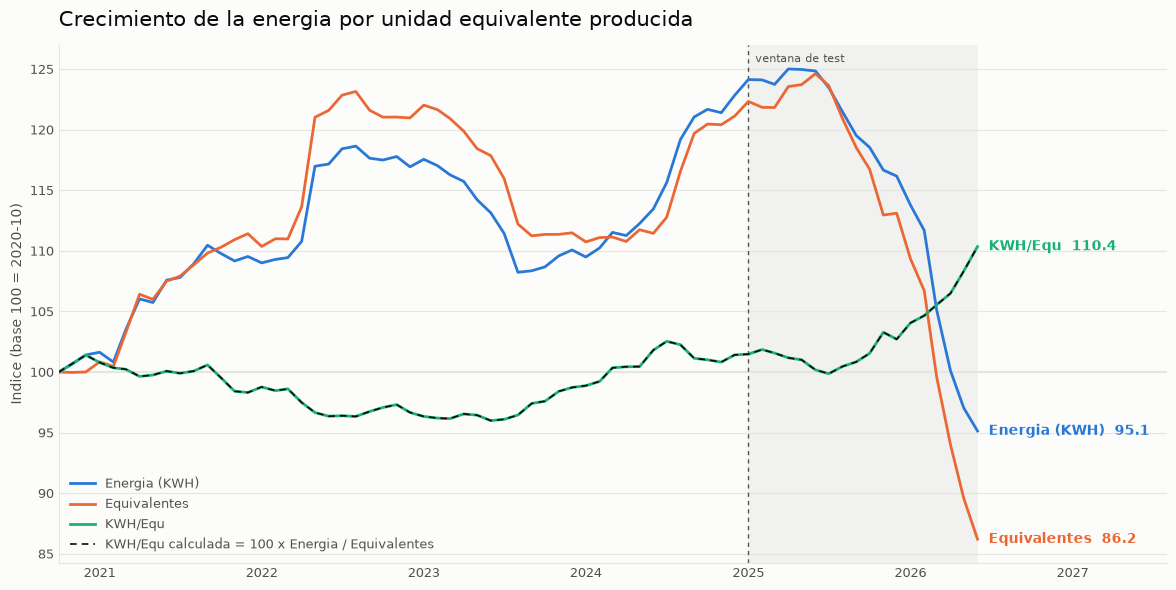

In [79]:
# Paleta validada (skill dataviz, slots 1-3, --pairs all)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"
SUPERFICIE, TINTA, TINTA_SUAVE, GRILLA = "#fcfcfb", "#0b0b0b", "#52514e", "#e5e5e2"

fig, ax = plt.subplots(figsize=(12, 6), facecolor=SUPERFICIE)
ax.set_facecolor(SUPERFICIE)

ax.axhline(100, color=GRILLA, linewidth=1.5, zorder=1)
series = [
    ("Energia (KWH)", C_ENERGIA),
    ("Equivalentes", C_EQUIV),
    ("KWH/Equ", C_RAZON),
]
for nombre, color in series:
    ax.plot(idx.index, idx[nombre], color=color, linewidth=2, label=nombre, zorder=3)

# Curva combinada calculada: debe caer exactamente sobre KWH/Equ medido
ax.plot(
    idx.index,
    idx["KWH/Equ (calculada)"],
    color=TINTA,
    linewidth=1.2,
    linestyle=(0, (4, 3)),
    zorder=4,
    label="KWH/Equ calculada = 100 x Energia / Equivalentes",
)

# Etiquetas directas (obligatorias: el verde queda por debajo de 3:1 de contraste)
for nombre, color in series:
    y = idx[nombre].iloc[-1]
    ax.annotate(
        f"{nombre}  {y:,.1f}",
        xy=(idx.index[-1], y),
        xytext=(8, 0),
        textcoords="offset points",
        color=color,
        fontsize=10,
        fontweight="bold",
        va="center",
    )

# La banda queda dentro de los datos; las etiquetas directas viven en el margen
# de 14 meses que anade set_xlim, asi que no se solapan con ella.
marcar_test(ax, idx.index[0], idx.index[-1], etiqueta=True)

ax.set_title(
    "Crecimiento de la energia por unidad equivalente producida",
    fontsize=15,
    color=TINTA,
    loc="left",
    pad=14,
)
ax.set_ylabel("Indice (base 100 = 2020-10)", fontsize=10, color=TINTA_SUAVE)
ax.grid(axis="y", color=GRILLA, linewidth=0.8)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color(GRILLA)
ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
ax.set_xlim(idx.index[0], idx.index[-1] + pd.DateOffset(months=14))
ax.legend(loc="lower left", frameon=False, fontsize=9, labelcolor=TINTA_SUAVE)

plt.tight_layout()
plt.show()

In [80]:
# Metricas explicitas del resumen de abajo
base, final = idx.iloc[0], idx.iloc[-1]
niveles = {"Energia (KWH)": energia, "Equivalentes": equiv, "KWH/Equ": razon}

metricas_energia = pd.DataFrame(
    [
        {
            "serie": nombre,
            "nivel_base": s.dropna().iloc[0],
            "nivel_final": s.dropna().iloc[-1],
            "indice": final[nombre],
            "cambio_pct": final[nombre] - 100,
        }
        for nombre, s in niveles.items()
    ]
).round(2)

# La identidad de la curva combinada, verificada y no asumida
identidad_ok = np.allclose(idx["KWH/Equ"], 100 * idx["Energia (KWH)"] / idx["Equivalentes"])
print(f"base={idx.index[0]:%Y-%m}  final={idx.index[-1]:%Y-%m}  identidad_exacta={identidad_ok}")
metricas_energia

base=2020-10  final=2026-06  identidad_exacta=True


,serie,nivel_base,nivel_final,indice,cambio_pct
0,Energia (KWH),515412.17,490356.58,95.14,-4.86
1,Equivalentes,88173.19,76016.26,86.21,-13.79
2,KWH/Equ,5.85,6.45,110.35,10.35


### Resumen: la energia por bateria sube, pero no por gastar mas

Serie de planta (`OREC`), media movil de 12 meses, indice base 100 en 2020-10:

| serie | nivel base (2020-10) | nivel final (2026-06) | indice |
|---|---|---|---|
| Energia | 515,412 kWh/mes | 490,357 kWh/mes | **95.14** |
| Equivalentes | 88,173 | 76,016 | **86.21** |
| `KWH/Equ` | 5.85 | 6.45 | **110.35** |

**El consumo de energia bajo 4.86 %.** Aun asi la energia por unidad equivalente subio
**10.35 %**, porque la produccion cayo mas rapido: **-13.79 %**. La planta no esta gastando
mas energia, esta sacando menos producto por cada kWh. Una sola linea de `KWH/Equ` mostraria
la subida pero no la causa; la descomposicion separa las dos cosas.

**La curva combinada cierra exacta.** La linea punteada es `100 x Energia_idx /
Equivalentes_idx` y cae encima de la medida (el `assert` de la celda anterior lo verifica).
No es una aproximacion: es la misma identidad `KWH/Equ = energia / equivalentes` leida en
forma de indices.

Notas de metodo: la media movil de 12 meses descarta los primeros 11 meses, por eso la
serie arranca en 2020-10. La razon se calcula sobre las series suavizadas, no promediando
razones mensuales, que daria un numero distinto.


## Series de tiempo por proceso

Solo 3 de las 8 variables varian entre procesos: `KWH por proceso`,
`Produccion (Equivalente)` y `KWH/Equ (Reales)`. Las otras (`KWH`, los costos,
`KWH/Equ (Presupuesto)`, `Indice`) son valores de planta repetidos en las 7 filas
del mes, asi que separarlas por proceso daria 7 paneles identicos.


In [81]:
VARS_PROC = ["KWH por proceso", "Produccion (Equivalente)", "KWH/Equ (Reales)"]

# Mismo cuidado que en la seccion de planta: inicio de mes ANTES de filtrar, si no
# junio 2026 queda con un solo proceso.
base_proc = df_orec.copy()
base_proc["Proceso"] = base_proc["Proceso "].str.strip()
base_proc["Mes"] = base_proc["Fecha"].dt.to_period("M").dt.to_timestamp()
base_proc = base_proc[base_proc["Mes"] <= "2026-06-01"]

# OREC es el total de planta: va primero, luego los 6 subprocesos
PROCESOS = ["OREC", *sorted(set(base_proc["Proceso"]) - {"OREC"})]

# Un DataFrame Mes x Proceso por cada variable
series_proc = {
    v: base_proc.pivot_table(index="Mes", columns="Proceso", values=v, aggfunc="mean")[PROCESOS]
    for v in VARS_PROC
}
print(f"{len(PROCESOS)} procesos | {len(series_proc[VARS_PROC[0]])} meses")
series_proc["KWH por proceso"].tail(3).round(1)

7 procesos | 81 meses


Proceso,OREC,Cinta,Empaste Casting,Empaste Cominco,Empaste Expanded,Planta Oxido,Rejillas
Mes,,,,,,,
2026-04-01,315157.5,40970.5,34667.3,50425.2,0.0,135517.7,53576.8
2026-05-01,448000.0,58240.0,49280.0,71680.0,0.0,192640.0,76160.0
2026-06-01,506000.0,65780.0,55660.0,80960.0,0.0,217580.0,86020.0


In [82]:
series_proc.keys()

dict_keys(['KWH por proceso', 'Produccion (Equivalente)', 'KWH/Equ (Reales)'])

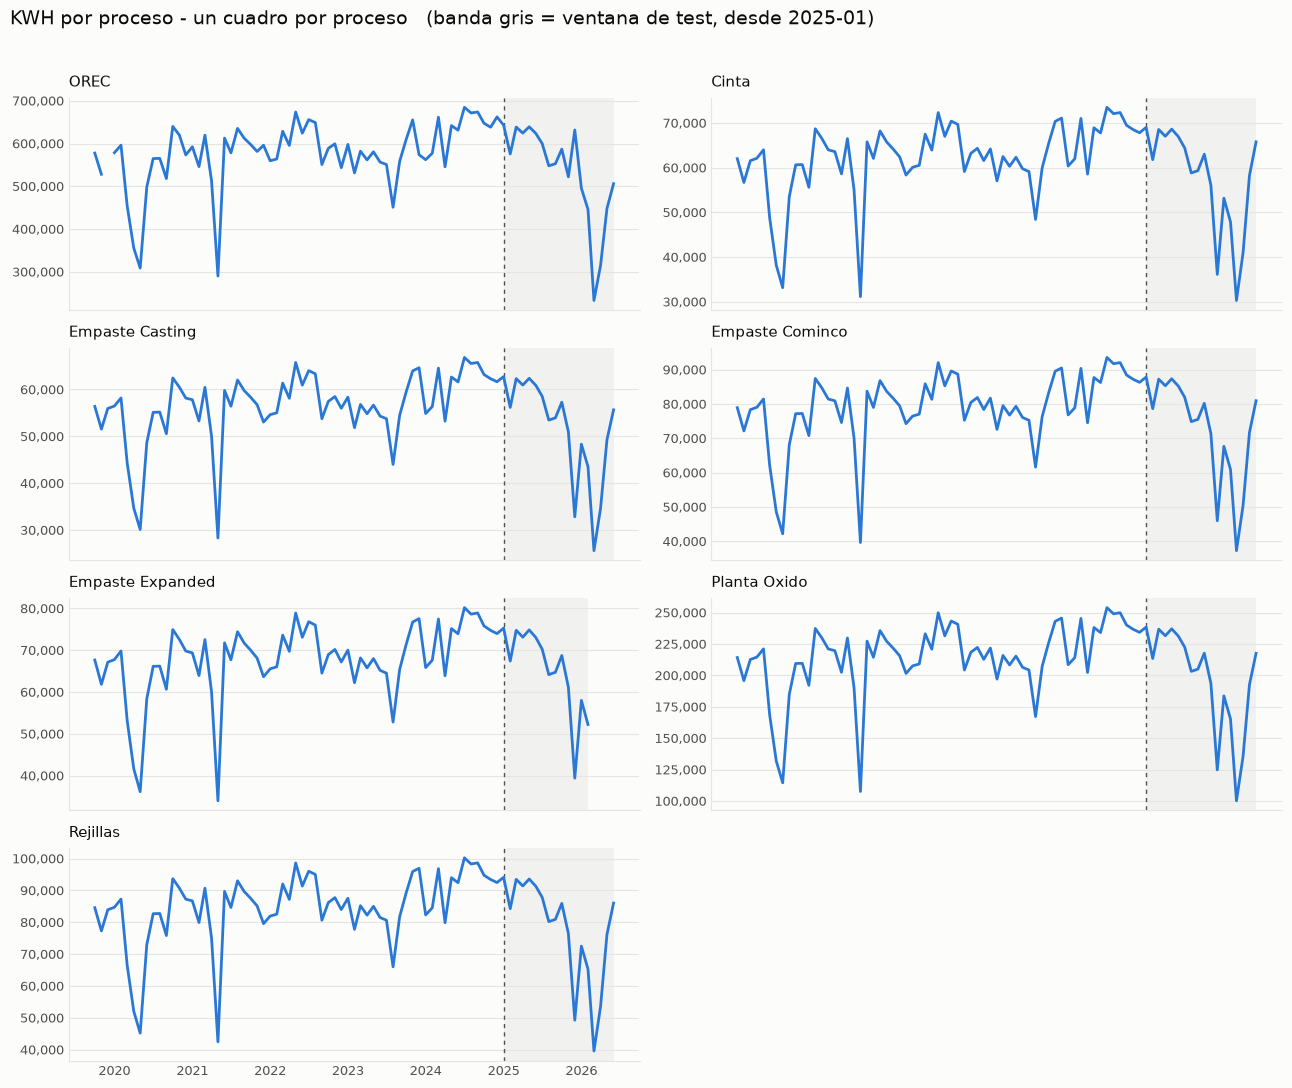

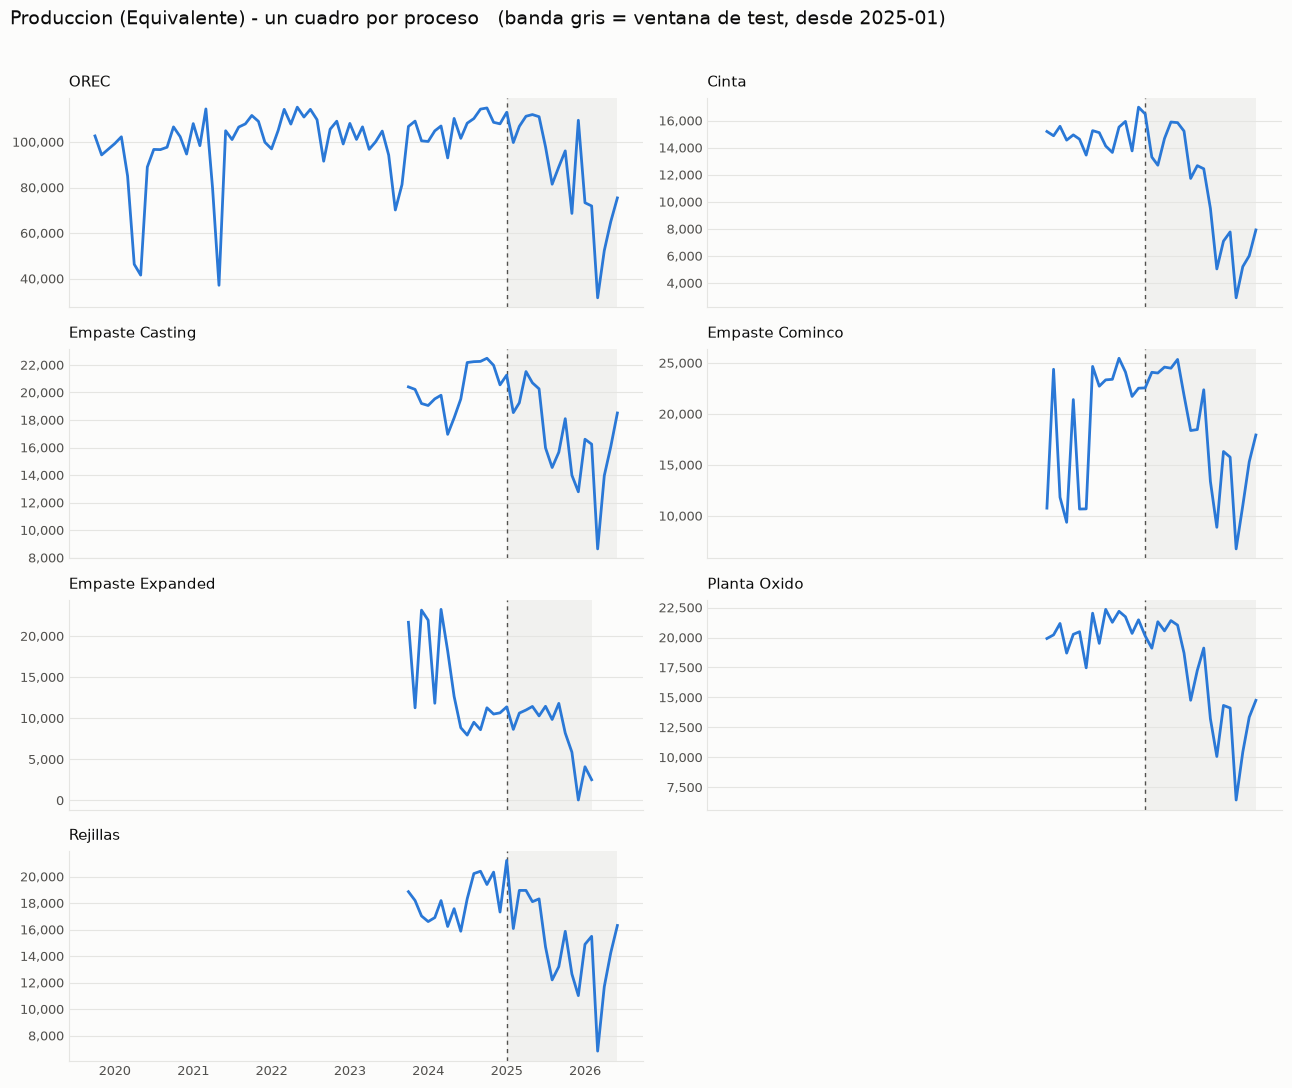

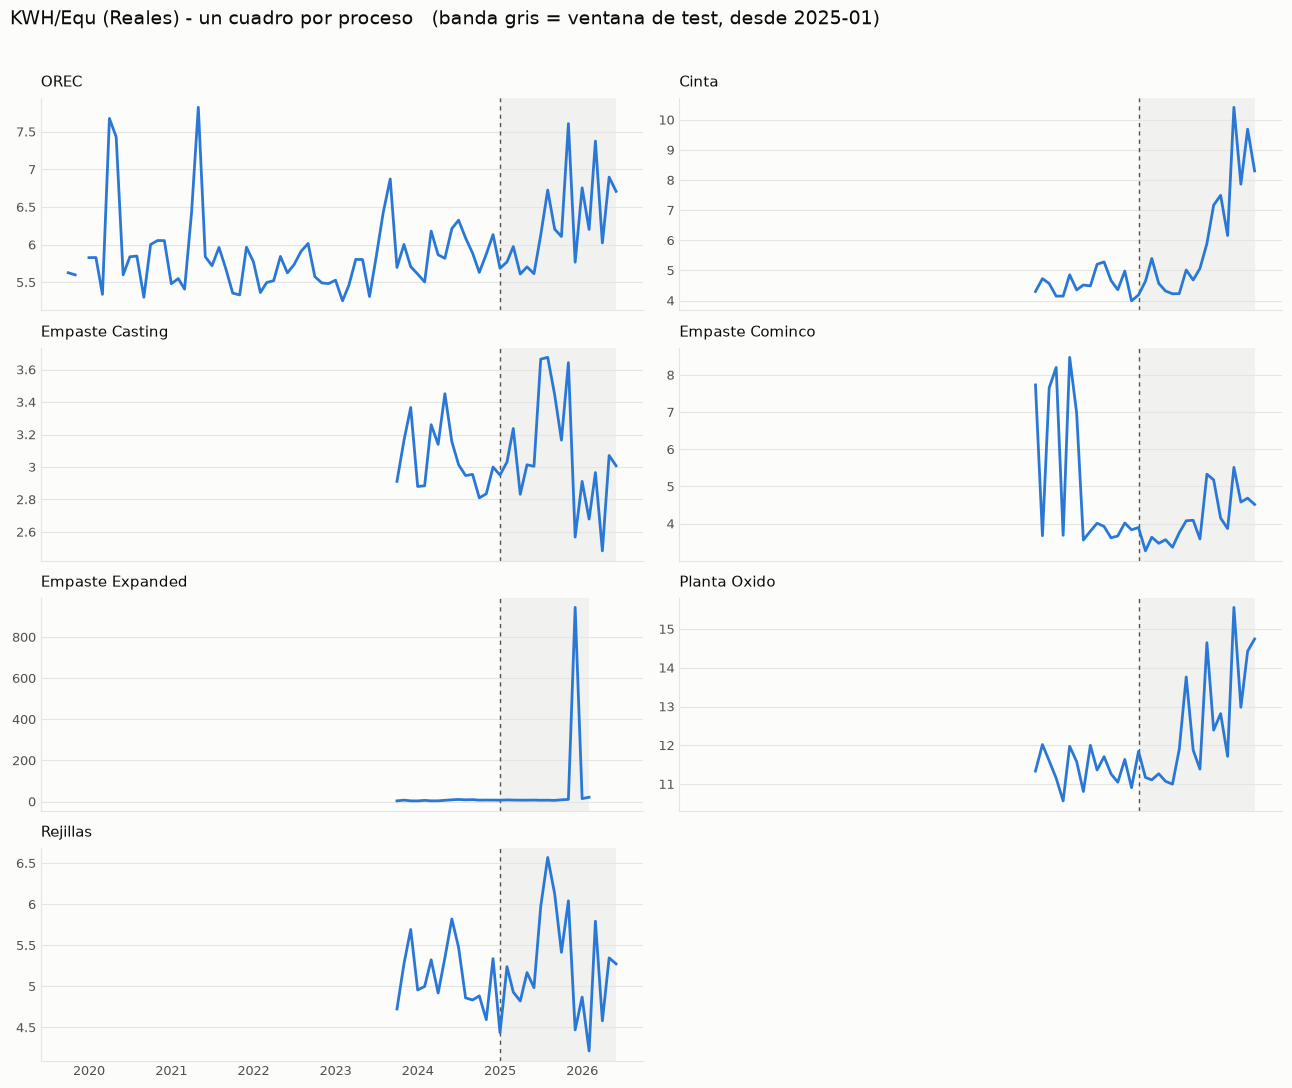

In [83]:
# Paleta validada (skill dataviz)
LINEA, SUPERFICIE = "#2a78d6", "#fcfcfb"
TINTA, TINTA_SUAVE, GRILLA = "#0b0b0b", "#52514e", "#e5e5e2"

# Por encima de este valor el eje se formatea con separador de miles y sin decimales
UMBRAL_MILES = 1000


def rejilla_procesos(titulo: str) -> tuple[plt.Figure, np.ndarray]:
    """Rejilla 4x2 con un cuadro por proceso (7 procesos, la 8a casilla se oculta)."""
    fig, axes = plt.subplots(4, 2, figsize=(13, 11), facecolor=SUPERFICIE, sharex=True)
    fig.suptitle(
        f"{titulo}   (banda gris = ventana de test, desde 2025-01)",
        fontsize=14,
        color=TINTA,
        x=0.01,
        ha="left",
        y=0.985,
    )
    for ax in axes.ravel():
        ax.set_facecolor(SUPERFICIE)
        ax.grid(axis="y", color=GRILLA, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.spines[["left", "bottom"]].set_color(GRILLA)
        ax.tick_params(colors=TINTA_SUAVE, labelsize=9, length=0)
        ax.yaxis.set_major_formatter(
            lambda v, _: f"{v:,.0f}" if abs(v) >= UMBRAL_MILES else f"{v:,.3g}"
        )
    axes.ravel()[-1].set_visible(False)
    return fig, axes


# Una figura por variable; dentro, un cuadro por proceso
for var in VARS_PROC:
    tabla = series_proc[var]
    fig, axes = rejilla_procesos(f"{var} - un cuadro por proceso")
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan)  # el cero aqui es 'no se registraba'
        ax.plot(s.index, s, color=LINEA, linewidth=2, zorder=3)
        ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)
    # sharex=True: todos los cuadros comparten el eje, se sombrea una vez por eje
    for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
        s = tabla[proc].replace(0, np.nan).dropna()
        if not s.empty:
            marcar_test(ax, s.index[0], s.index[-1])
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

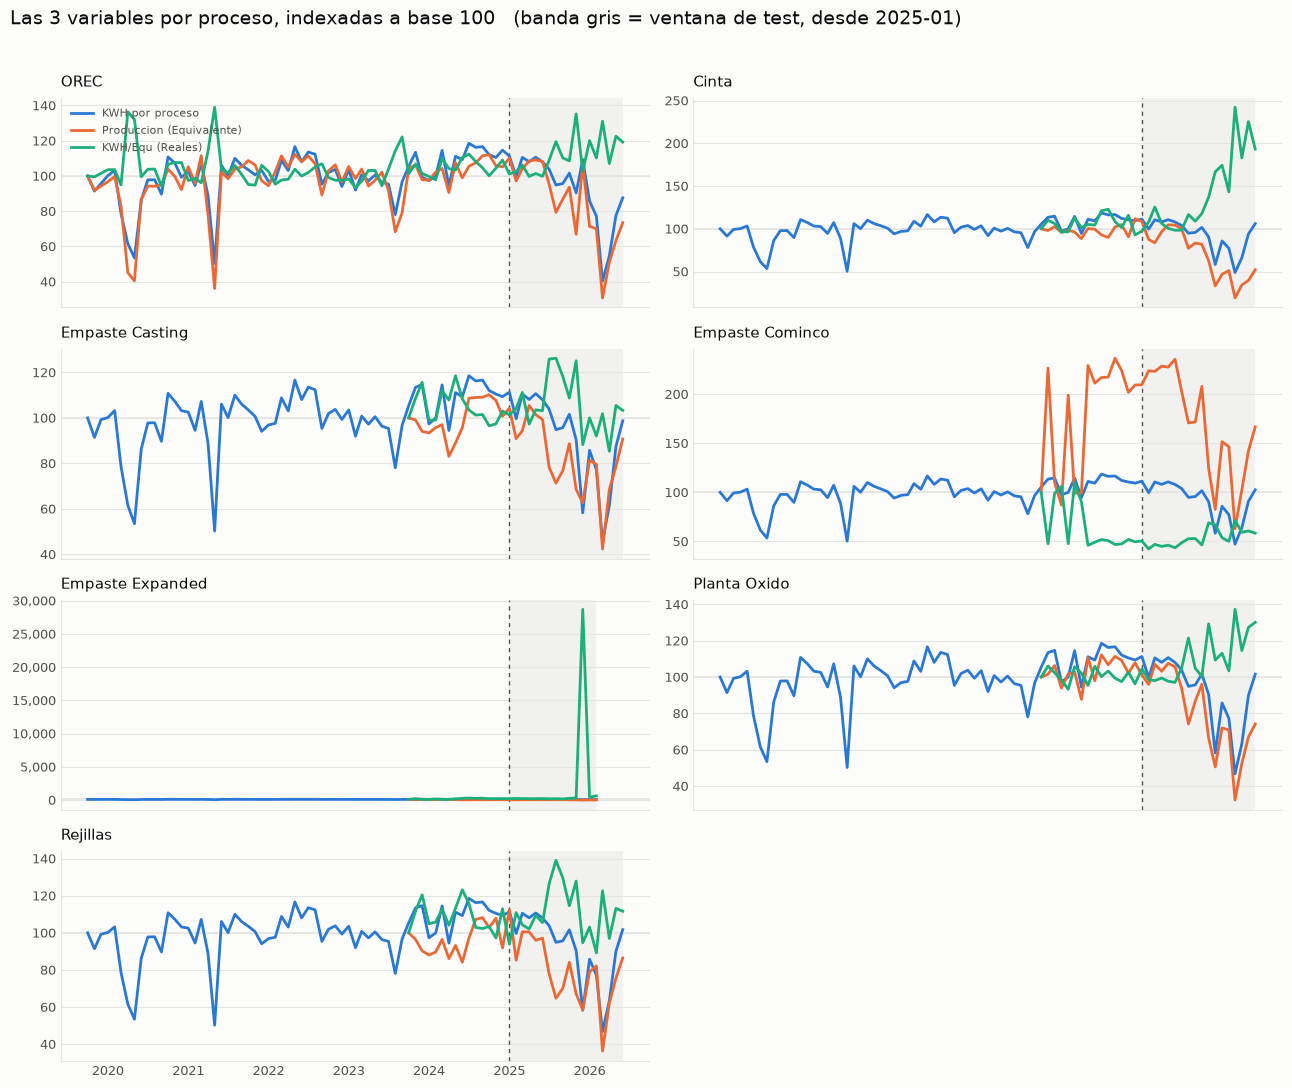

In [84]:
# Cuarta figura: un cuadro por proceso con las 3 variables indexadas a base 100,
# unica forma de verlas juntas (escalas de ~10^5, ~10^4 y ~5)
C_ENERGIA, C_EQUIV, C_RAZON = "#2a78d6", "#eb6834", "#1baf7a"

fig, axes = rejilla_procesos("Las 3 variables por proceso, indexadas a base 100")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    for var, color in zip(VARS_PROC, [C_ENERGIA, C_EQUIV, C_RAZON], strict=False):
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        if s.empty:
            continue
        ax.plot(s.index, 100 * s / s.iloc[0], color=color, linewidth=2, label=var, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    ax.set_title(proc, fontsize=10.5, color=TINTA, loc="left", pad=8)

for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    vistos = [series_proc[v][proc].replace(0, np.nan).dropna() for v in VARS_PROC]
    vistos = [s for s in vistos if not s.empty]
    if vistos:
        marcar_test(ax, min(s.index[0] for s in vistos), max(s.index[-1] for s in vistos))

axes.ravel()[0].legend(loc="upper left", frameon=False, fontsize=8, labelcolor=TINTA_SUAVE)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

In [85]:
# Metricas explicitas del resumen de abajo
filas = []
for proc in PROCESOS:
    fila = {"proceso": proc}
    for var in VARS_PROC:
        s = series_proc[var][proc].replace(0, np.nan).dropna()
        fila[f"{var} | meses"] = len(s)
        fila[f"{var} | desde"] = s.index.min().strftime("%Y-%m") if len(s) else "-"
    filas.append(fila)

metricas_series_proc = pd.DataFrame(filas)
metricas_series_proc

,proceso,KWH por proceso | meses,KWH por proceso | desde,Produccion (Equivalente) | meses,Produccion (Equivalente) | desde,KWH/Equ (Reales) | meses,KWH/Equ (Reales) | desde
0,OREC,80,2019-10,80,2019-10,80,2019-10
1,Cinta,81,2019-10,33,2023-10,33,2023-10
2,Empaste Casting,81,2019-10,33,2023-10,33,2023-10
3,Empaste Cominco,81,2019-10,33,2023-10,33,2023-10
4,Empaste Expanded,77,2019-10,29,2023-10,29,2023-10
5,Planta Oxido,81,2019-10,33,2023-10,33,2023-10
6,Rejillas,81,2019-10,33,2023-10,33,2023-10


### Resumen: series por proceso

- **Solo 3 variables varian por proceso.** `KWH`, los dos costos,
  `KWH/Equ (Presupuesto)` e `Indice` son cifras de planta repetidas en las 7 filas
  de cada mes.
- **La cobertura es muy despareja.** `KWH por proceso` existe en casi todos los
  meses (81; 80 en `OREC`, 77 en `Empaste Expanded`), pero `Produccion (Equivalente)` y
  `KWH/Equ (Reales)` solo existen desde **2024** en los subprocesos (33 meses, 29 en
  `Empaste Expanded`). `OREC` los tiene en los 80 meses porque es el total de planta.
- **Por eso los cuadros no empiezan a la vez.** El de `OREC` cubre 2019-2026 y los de
  los subprocesos arrancan en 2024: no es un hueco de datos, es cuando se empezo a
  medir produccion por proceso.


## Crecimiento de la energia por proceso

Misma descomposicion que a nivel de planta, ahora un cuadro por proceso. La ventana
de suavizado se adapta a la cobertura: **12 meses para `OREC`** (80 meses de
historia) y **3 meses para los subprocesos** (33 meses desde 2024), si no
quedarian en ~21 puntos.


In [86]:
# OREC reutiliza el indice ya calculado en la seccion de planta (`idx`), para que no
# existan dos cifras distintas de lo mismo en el notebook. Los subprocesos se calculan
# aparte con ventana de 3 meses, desde el primer mes con produccion registrada.
crecimiento = {
    "OREC": idx[["Energia (KWH)", "Equivalentes", "KWH/Equ"]].rename(
        columns={"Energia (KWH)": "Energia"}
    )
}

for proc in [x for x in PROCESOS if x != "OREC"]:
    e = series_proc["KWH por proceso"][proc]
    q = series_proc["Produccion (Equivalente)"][proc]
    inicio = q[q > 0].index.min()  # desde que se mide produccion en este proceso
    e, q = e.loc[inicio:].rolling(3).mean(), q.loc[inicio:].rolling(3).mean()
    comun = e.dropna().index.intersection(q.dropna().index)
    e, q = e.loc[comun], q.loc[comun]
    r = e / q
    crecimiento[proc] = pd.DataFrame(
        {
            "Energia": 100 * e / e.iloc[0],
            "Equivalentes": 100 * q / q.iloc[0],
            "KWH/Equ": 100 * r / r.iloc[0],
        }
    )

metricas_crecimiento_proc = pd.DataFrame(
    [
        {
            "proceso": proc,
            "ventana_meses": 12 if proc == "OREC" else 3,
            "puntos": len(tabla),
            "desde": tabla.index.min().strftime("%Y-%m"),
            "hasta": tabla.index.max().strftime("%Y-%m"),
            "KWH por proceso idx (final)": tabla["Energia"].iloc[-1],
            "Produccion (Equivalente) idx (final)": tabla["Equivalentes"].iloc[-1],
            "KWH/Equ idx (final)": tabla["KWH/Equ"].iloc[-1],
        }
        for proc, tabla in crecimiento.items()
    ]
).round(1)

# La identidad combinada tiene que cerrar en cada proceso
assert all(
    np.allclose(t["KWH/Equ"], 100 * t["Energia"] / t["Equivalentes"]) for t in crecimiento.values()
), "la identidad no cierra en algun proceso"
metricas_crecimiento_proc

,proceso,ventana_meses,puntos,desde,hasta,KWH por proceso idx (final),Produccion (Equivalente) idx (final),KWH/Equ idx (final)
0,OREC,12,69,2020-10,2026-06,95.1,86.2,110.4
1,Cinta,3,31,2023-12,2026-06,79.8,41.9,190.3
2,Empaste Casting,3,31,2023-12,2026-06,74.3,81.1,91.6
3,Empaste Cominco,3,31,2023-12,2026-06,77.2,94.2,81.9
4,Empaste Expanded,3,28,2023-12,2026-03,48.9,11.8,415.6
5,Planta Oxido,3,31,2023-12,2026-06,76.4,62.9,121.5
6,Rejillas,3,31,2023-12,2026-06,76.5,78.1,97.9


In [87]:
crecimiento.keys()

dict_keys(['OREC', 'Cinta', 'Empaste Casting', 'Empaste Cominco', 'Empaste Expanded', 'Planta Oxido', 'Rejillas'])

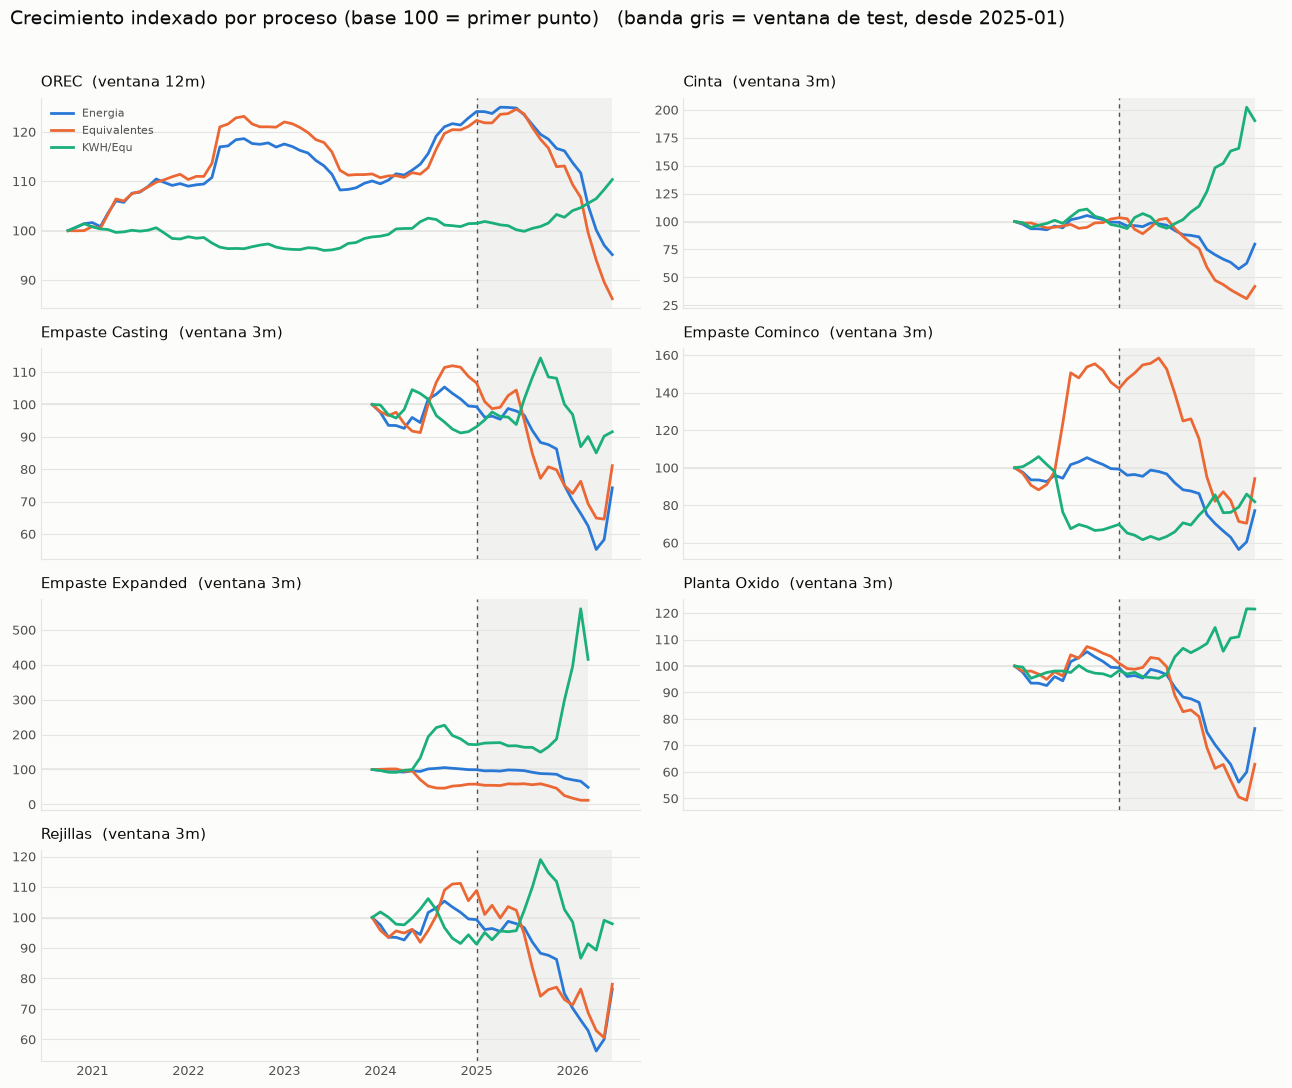

In [88]:
fig, axes = rejilla_procesos("Crecimiento indexado por proceso (base 100 = primer punto)")
for ax, proc in zip(axes.ravel(), PROCESOS, strict=False):
    tabla = crecimiento[proc]
    for col, color in zip(
        ["Energia", "Equivalentes", "KWH/Equ"], [C_ENERGIA, C_EQUIV, C_RAZON], strict=False
    ):
        ax.plot(tabla.index, tabla[col], color=color, linewidth=2, label=col, zorder=3)
    ax.axhline(100, color=GRILLA, linewidth=1.2, zorder=1)
    # cada panel termina en una fecha distinta (Empaste Expanded para en 2026-03)
    marcar_test(ax, tabla.index[0], tabla.index[-1])
    ventana = 12 if proc == "OREC" else 3
    ax.set_title(f"{proc}  (ventana {ventana}m)", fontsize=10.5, color=TINTA, loc="left", pad=8)

axes.ravel()[0].legend(loc="upper left", frameon=False, fontsize=8, labelcolor=TINTA_SUAVE)
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

### Resumen: crecimiento por proceso

| proceso | energia | equivalentes | KWH/Equ |
|---|---|---|---|
| `OREC` (planta, 12m) | 95.1 | 86.2 | **110.4** |
| `Cinta` | 79.8 | 41.9 | **190.3** |
| `Empaste Casting` | 74.3 | 81.1 | 91.6 |
| `Empaste Cominco` | 77.2 | 94.2 | **81.9** |
| `Empaste Expanded` | 48.9 | 11.8 | **415.6** |
| `Planta Oxido` | 76.4 | 62.9 | 121.5 |
| `Rejillas` | 76.5 | 78.1 | 97.9 |

- **Todos los procesos bajaron su consumo** (indices de 48.9 a 79.8, entre -20 % y
  -51 %). El problema nunca fue gastar mas energia.
- **Lo que decide el resultado es cuanto cayo la produccion.** `Empaste Cominco` casi
  la sostuvo (94.2) y mejoro su intensidad un 18 %; `Empaste Expanded` se desplomo a
  11.8 y su intensidad se multiplico por 4.2.
- **El +10.4 % de planta esconde comportamientos opuestos.** Tres procesos mejoraron
  (`Empaste Cominco`, `Empaste Casting`, `Rejillas`) y dos empeoraron fuerte (`Cinta`
  +90 %, `Empaste Expanded` +316 %). Ahi esta el margen de mejora, no en el promedio.
- Las ventanas no son comparables entre si: `OREC` cubre 2020-2026 con ventana de 12
  meses y los subprocesos desde 2023-12 con ventana de 3.


En general la planta y el desgloce por linea muestran como se bajo la producción y el consumo, sin embargo la producción baja mas rapido que el consumo de ahí que `KWH/Equ` aumente, esto es un posible problema en el cual se debe ahondar mas para buscar sus causas.
